# ⚾ Chicago Cubs Pitching Analytics Lab
### Statistical modelling · Bayesian inference · Machine learning · Monte Carlo simulation · Interactive baseball visuals

**Data:** Statcast pitch-by-pitch export (`Cubs.csv`), regular season, Jul 2023 – Jun 2026.

> **Scope note (verified in the data-loading section):** the file contains **4-seam fastballs thrown by Cubs pitchers** (opponents batting). It contains no Cubs hitting and no other pitch types, so this project is a *Cubs fastball / pitching* study. Every model is built and labelled with that in mind.

---
## Roadmap

| # | Section | What you get |
|---|---------|--------------|
| 1 | Setup & data engineering | Cleaning, pitcher names, outcome/base-state features |
| 2 | Exploratory analysis | Season/pitcher summaries, velocity trends |
| 3 | Baseball visuals (static) | Strike-zone surfaces, spray chart, movement & release plots, pitcher card |
| 4 | Interactive visuals | Zone explorer, spray chart, 3-D pitch trajectories, dashboards |
| 5 | Statistical models | Run values, absorbing Markov count-chain, regression, hypothesis tests, mixed model |
| 6 | Bayesian models | Hierarchical whiff model (PyMC), shrinkage, change-point model |
| 7 | Machine learning | Pitch-outcome classifier, SHAP, Stuff+ score, pitcher archetypes, velocity counterfactuals |
| 8 | Monte Carlo simulation | PA/inning/game simulator, simulated RE24, uncertainty-aware pitcher ranking, velocity scenarios |
| 9 | Findings, limitations, exports | Summary, CSV/HTML exports |

**How to run:** `pip install pandas numpy scipy matplotlib seaborn plotly scikit-learn lightgbm shap statsmodels pymc arviz pybaseball` then *Run All*. Put `Cubs.csv` next to the notebook (or edit `DATA_CANDIDATES`).

## 1 · Setup & data engineering

In [1]:
import warnings, time, math, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Arc, Wedge, Ellipse, Circle
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from scipy.ndimage import gaussian_filter
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

# ---- configuration -------------------------------------------------------
DATA_CANDIDATES = ["Cubs.csv", "data/Cubs.csv", "/mnt/user-data/uploads/Cubs.csv"]
OUT_DIR = Path("cubs_outputs"); (OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
MIN_PITCHES = 150        # minimum fastballs for pitcher-level leaderboards
# Plotly renderer: "plotly_mimetype+notebook_connected" works in Jupyter/VS Code.
# Use "colab" in Google Colab, or "browser" if running as a plain script.
pio.renderers.default = "plotly_mimetype+notebook_connected"

# ---- style ---------------------------------------------------------------
CUBS_BLUE, CUBS_RED, GREY = "#0E3386", "#CC3433", "#6b7280"
OUTCOME_COLORS = {"Ball": "#9ca3af", "Called Strike": "#CC3433", "Swinging Strike": "#7f1d1d",
                  "Foul": "#f59e0b", "In Play": "#0E3386", "HBP": "#111827"}
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
PLOTLY_TEMPLATE = "plotly_white"
px.defaults.template = PLOTLY_TEMPLATE

def save_fig(fig, name):
    # Save an interactive Plotly figure as a standalone, shareable HTML file.
    fig.write_html(OUT_DIR / "figures" / f"{name}.html", include_plotlyjs="cdn")

print("Setup complete.")

Setup complete.


In [3]:
def find_data():
    for p in DATA_CANDIDATES:
        if Path(p).exists():
            return Path(p)
    raise FileNotFoundError(f"Cubs.csv not found. Looked in: {DATA_CANDIDATES}")

DATA_PATH = find_data()
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns from {DATA_PATH}")

# ---- verify what the file actually contains -----------------------------
cubs_pitching = (((raw.home_team == "CHC") & (raw.inning_topbot == "Top")) |
                 ((raw.away_team == "CHC") & (raw.inning_topbot == "Bot")))
scope = pd.Series({
    "Pitches": f"{len(raw):,}",
    "Games": raw.game_pk.nunique(),
    "Cubs pitchers": raw.pitcher.nunique(),
    "Opposing batters": raw.batter.nunique(),
    "Pitch types in file": ", ".join(sorted(raw.pitch_type.dropna().unique())),
    "Share of pitches with Cubs pitching": f"{cubs_pitching.mean():.1%}",
    "Game types": ", ".join(sorted(raw.game_type.unique())),
    "Date range": f"{pd.to_datetime(raw.game_date).min():%Y-%m-%d} to {pd.to_datetime(raw.game_date).max():%Y-%m-%d}",
}, name="value")
display(scope.to_frame())

empty_cols = raw.columns[raw.isna().all()].tolist()
print(f"\nFully-empty columns dropped ({len(empty_cols)}): {empty_cols}")

Loaded 25,000 rows x 119 columns from Cubs.csv


,value
Pitches,"25,000"
Games,472
Cubs pitchers,71
Opposing batters,633
Pitch types in file,FF
Share of pitches with Cubs pitching,100.0%
Game types,R
Date range,2023-07-26 to 2026-06-30



Fully-empty columns dropped (8): ['spin_dir', 'spin_rate_deprecated', 'break_angle_deprecated', 'break_length_deprecated', 'tfs_deprecated', 'tfs_zulu_deprecated', 'umpire', 'sv_id']


In [4]:
# ---- pitcher names (MLBAM id -> name). Cached after first lookup; falls back to ids offline ----
def get_pitcher_names(ids, cache=OUT_DIR / "pitcher_names.csv"):
    names = {}
    if cache.exists():
        names = pd.read_csv(cache).set_index("mlbam")["name"].to_dict()
    missing = [i for i in ids if i not in names]
    if missing:
        try:
            from pybaseball import playerid_reverse_lookup
            lk = playerid_reverse_lookup(missing, key_type="mlbam")
            for _, r in lk.iterrows():
                names[int(r.key_mlbam)] = f"{str(r.name_first).title()} {str(r.name_last).title()}"
        except Exception as e:
            print("Name lookup unavailable (", type(e).__name__, ") - using ids for missing names.")
    for i in ids:
        names.setdefault(i, f"Pitcher {i}")
    pd.Series(names, name="name").rename_axis("mlbam").reset_index().to_csv(cache, index=False)
    return names

PITCHER_NAMES = get_pitcher_names(raw.pitcher.unique().tolist())
# make labels unique if two pitchers share a name
_dup = pd.Series(PITCHER_NAMES).duplicated(keep=False)
for k in _dup[_dup].index:
    PITCHER_NAMES[k] = f"{PITCHER_NAMES[k]} ({k})"
print(f"Resolved {len(PITCHER_NAMES)} pitcher names, e.g.:", list(PITCHER_NAMES.values())[:5])

Resolved 71 pitcher names, e.g.: ['Héctor Neris', 'Javier Assad', 'Matt Boyd', 'Brooks Kriske', 'Nate Pearson']


In [5]:
RESULT_MAP = {
    "ball": "Ball", "blocked_ball": "Ball",
    "called_strike": "Called Strike",
    "swinging_strike": "Swinging Strike", "swinging_strike_blocked": "Swinging Strike",
    "foul_tip": "Swinging Strike", "missed_bunt": "Swinging Strike", "bunt_foul_tip": "Swinging Strike",
    "automatic_ball": "Ball", "pitchout": "Ball", "automatic_strike": "Called Strike", "foul_pitchout": "Foul",
    "foul": "Foul", "foul_bunt": "Foul",
    "hit_into_play": "In Play", "hit_by_pitch": "HBP",
}
EVENT_MAP = {
    "strikeout": "K", "strikeout_double_play": "K", "walk": "BB", "hit_by_pitch": "HBP",
    "single": "1B", "double": "2B", "triple": "3B", "home_run": "HR",
    "field_error": "ROE",
}
BASE_LABELS = {0: "Empty", 1: "1B", 2: "2B", 3: "1B-2B", 4: "3B", 5: "1B-3B", 6: "2B-3B", 7: "Loaded"}

def engineer(raw):
    df = raw.drop(columns=raw.columns[raw.isna().all()]).copy()
    df["game_date"] = pd.to_datetime(df["game_date"])
    df = df.sort_values(["game_date", "game_pk", "at_bat_number", "pitch_number"]).reset_index(drop=True)

    # identities (NB: Statcast `player_name` is the BATTER)
    df["pitcher_name"] = df["pitcher"].map(PITCHER_NAMES)
    df["batter_name"] = df["player_name"]
    df["season"] = df["game_year"]
    df["month"] = df["game_date"].dt.month
    df["cubs_home"] = df["home_team"].eq("CHC")
    df["opp"] = np.where(df["cubs_home"], df["away_team"], df["home_team"])

    # pitch result + swing/whiff flags
    df["result"] = df["description"].map(RESULT_MAP).fillna("Other")
    df["is_swing"] = df["result"].isin(["Swinging Strike", "Foul", "In Play"])
    df["is_whiff"] = df["result"].eq("Swinging Strike")
    df["is_called_strike"] = df["result"].eq("Called Strike")
    df["is_take"] = df["result"].isin(["Ball", "Called Strike", "HBP"])
    df["is_csw"] = df["result"].isin(["Called Strike", "Swinging Strike"])
    df["in_zone"] = df["zone"].between(1, 9)
    df["is_chase"] = df["is_swing"] & ~df["in_zone"]
    df["is_bip"] = df["result"].eq("In Play")

    # counts / state
    df["count"] = df["balls"].astype(str) + "-" + df["strikes"].astype(str)
    df["base_code"] = (df.on_1b.notna() * 1 + df.on_2b.notna() * 2 + df.on_3b.notna() * 4).astype(int)
    df["bases"] = df["base_code"].map(BASE_LABELS)
    df["runners_on"] = df["base_code"] > 0
    df["platoon_adv"] = df["stand"].ne(df["p_throws"])          # True = opposite-handed matchup
    df["tto"] = df["n_thruorder_pitcher"].clip(upper=3)          # times through the order faced by pitcher

    # movement / location, normalised so +ve = arm-side / inside
    df["armside_in"] = np.where(df.p_throws.eq("R"), -df.pfx_x, df.pfx_x) * 12
    df["ivb_in"] = df.pfx_z * 12
    df["release_x_norm"] = np.where(df.p_throws.eq("R"), df.release_pos_x, -df.release_pos_x)  # +ve = arm-side
    df["inside_x"] = np.where(df.stand.eq("R"), -df.plate_x, df.plate_x)

    # plate-appearance end + grouped event
    df["pa_end"] = df["events"].notna()
    df["ev_group"] = df["events"].map(EVENT_MAP)
    df.loc[df["events"].notna() & df["ev_group"].isna(), "ev_group"] = "Out"

    # run values (Statcast: delta_run_exp is from the batting team's view)
    df["rv_pitcher"] = df["delta_pitcher_run_exp"]
    df["rv_batter"] = df["delta_run_exp"]

    # position in the appearance (fastball index)
    df["ff_idx"] = df.groupby(["game_pk", "pitcher"]).cumcount() + 1
    df["game_no"] = df["game_date"].rank(method="dense").astype(int)

    # spray-chart coordinates in feet (home plate at hc ~ (125.4, 198.3); ~2.5 ft per unit)
    df["spray_x"] = (df.hc_x - 125.42) * 2.5
    df["spray_y"] = (198.27 - df.hc_y) * 2.5
    df["spray_angle"] = np.degrees(np.arctan2(df.spray_x, df.spray_y))   # 0 = CF, -45 = LF line, +45 = RF line
    return df

df = engineer(raw)
assert (df["result"] != "Other").all(), f"Unmapped pitch results: {df.loc[df.result == 'Other', 'description'].unique()}"
print(f"Engineered table: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(df["result"].value_counts().to_frame("pitches").assign(pct=lambda d: (d.pitches / d.pitches.sum()).round(3)))

Engineered table: 25,000 rows x 145 columns
                 pitches    pct
result                         
Ball                8105  0.324
Foul                5461  0.218
Called Strike       4616  0.185
In Play             4477  0.179
Swinging Strike     2297  0.092
HBP                   44  0.002


### Key fields used in this project

| Field | Meaning |
|---|---|
| `release_speed`, `release_spin_rate`, `spin_axis`, `release_extension` | Velocity (mph), spin (rpm), spin direction, extension (ft) |
| `armside_in`, `ivb_in` | Arm-side run and induced vertical break in inches (derived from `pfx_x/pfx_z`; positive = arm-side / rising) |
| `plate_x`, `plate_z`, `zone` | Location crossing the plate (ft) and Statcast zone (1-9 in zone, 11-14 out) |
| `result` | Pitch result: Ball / Called Strike / Swinging Strike / Foul / In Play / HBP |
| `launch_speed`, `launch_angle`, `estimated_woba_using_speedangle` | Batted-ball quality (exit velo, launch angle, xwOBA) |
| `delta_pitcher_run_exp` → `rv_pitcher` | Change in run expectancy from the pitcher's view (positive = good for the pitcher) |
| `bases`, `outs_when_up`, `balls`, `strikes`, `tto` | Game state |

## 2 · Exploratory data analysis

In [6]:
# ---- data-quality profile of the columns we rely on ----
key_cols = ["release_speed", "release_spin_rate", "spin_axis", "release_extension", "pfx_x", "pfx_z",
            "plate_x", "plate_z", "arm_angle", "launch_speed", "launch_angle", "hit_distance_sc",
            "estimated_woba_using_speedangle", "bat_speed", "swing_length", "delta_run_exp"]
dq = pd.DataFrame({"missing_%": (df[key_cols].isna().mean() * 100).round(1),
                   "n_valid": df[key_cols].notna().sum()})
display(dq.T)
print("Note: batted-ball fields are only populated when the ball is put in play; bat-tracking only on swings with tracking.")

,release_speed,release_spin_rate,spin_axis,release_extension,pfx_x,pfx_z,plate_x,plate_z,arm_angle,launch_speed,launch_angle,hit_distance_sc,estimated_woba_using_speedangle,bat_speed,swing_length,delta_run_exp
missing_%,0.0,0.2,0.2,0.0,0.0,0.0,0.0,0.0,0.4,62.4,62.3,62.4,75.0,53.2,53.2,0.0
n_valid,25000.0,24940.0,24940.0,24991.0,25000.0,25000.0,25000.0,25000.0,24909.0,9409.0,9415.0,9402.0,6254.0,11696.0,11696.0,25000.0


Note: batted-ball fields are only populated when the ball is put in play; bat-tracking only on swings with tracking.


In [7]:
def pitch_metrics(g):
    # Core fastball metrics for any slice of the data.
    swings, takes, bip = g[g.is_swing], g[g.is_take], g[g.is_bip]
    pa = g[g.pa_end]
    return pd.Series({
        "pitches": len(g), "games": g.game_pk.nunique(),
        "velo": g.release_speed.mean(), "spin": g.release_spin_rate.mean(),
        "ivb_in": g.ivb_in.mean(), "armside_in": g.armside_in.mean(), "ext_ft": g.release_extension.mean(),
        "zone_%": g.in_zone.mean() * 100,
        "whiff/swing_%": swings.is_whiff.mean() * 100 if len(swings) else np.nan,
        "chase_%": g[~g.in_zone].is_swing.mean() * 100,
        "CSW_%": g.is_csw.mean() * 100,
        "hardhit_%": (bip.launch_speed >= 95).mean() * 100 if bip.launch_speed.notna().any() else np.nan,
        "barrel_%": (bip.launch_speed_angle == 6).sum() / max(bip.launch_speed_angle.notna().sum(), 1) * 100,
        "xwOBAcon": bip.estimated_woba_using_speedangle.mean(),
        "wOBA_end": pa.woba_value.sum() / pa.woba_denom.sum() if pa.woba_denom.sum() > 0 else np.nan,
        "RV/100": g.rv_pitcher.mean() * 100,
    })

season_tbl = df.groupby("season").apply(pitch_metrics).round(2)
display(season_tbl)
print("RV/100 = runs saved per 100 fastballs from the pitcher's perspective (positive = good). wOBA_end uses only plate appearances that ended on a fastball.")

,pitches,games,velo,spin,ivb_in,armside_in,ext_ft,zone_%,whiff/swing_%,chase_%,CSW_%,hardhit_%,barrel_%,xwOBAcon,wOBA_end,RV/100
season,,,,,,,,,,,,,,,,
2023,2697.0,62.0,93.38,2305.35,14.06,4.88,6.45,54.65,21.32,20.36,27.96,49.87,9.77,0.43,0.39,-0.51
2024,8071.0,162.0,92.99,2305.75,15.09,5.87,6.56,58.21,19.24,22.80,28.16,46.18,9.88,0.39,0.34,0.11
2025,10042.0,162.0,94.15,2359.59,15.78,6.83,6.44,58.89,17.13,24.37,27.23,48.36,11.48,0.39,0.33,0.29
2026,4190.0,86.0,93.84,2319.69,15.63,8.25,6.50,53.96,20.32,28.25,27.49,47.29,12.19,0.42,0.36,-0.26


RV/100 = runs saved per 100 fastballs from the pitcher's perspective (positive = good). wOBA_end uses only plate appearances that ended on a fastball.


In [8]:
# ---- league-style leaderboard for Cubs pitchers (min pitches) ----
pitcher_tbl = (df.groupby(["pitcher", "pitcher_name", "p_throws"]).apply(pitch_metrics)
                 .reset_index().query("pitches >= @MIN_PITCHES").sort_values("RV/100", ascending=False))
pitcher_tbl[["pitches", "games"]] = pitcher_tbl[["pitches", "games"]].astype(int)
print(f"{len(pitcher_tbl)} pitchers with >= {MIN_PITCHES} fastballs")
display(pitcher_tbl.round(2).reset_index(drop=True).head(15))

29 pitchers with >= 150 fastballs


,pitcher,pitcher_name,p_throws,pitches,games,velo,spin,ivb_in,armside_in,ext_ft,zone_%,whiff/swing_%,chase_%,CSW_%,hardhit_%,barrel_%,xwOBAcon,wOBA_end,RV/100
0,623167,Chris Flexen,R,277,21,92.43,2244.86,17.74,2.16,6.19,54.87,13.99,29.60,22.38,43.86,14.04,0.37,0.23,2.60
1,641745,Brad Keller,R,470,68,97.18,2382.36,15.11,1.40,5.96,59.79,17.14,20.63,30.85,36.11,8.33,0.32,0.30,1.73
2,519141,Drew Pomeranz,L,614,57,92.73,2641.80,17.06,1.16,5.80,59.61,24.06,29.03,31.76,42.72,7.77,0.37,0.27,1.57
3,668338,Tyson Miller,R,345,48,89.44,2166.32,9.77,1.87,7.29,55.07,29.76,20.65,31.59,50.00,10.42,0.40,0.27,1.37
4,690990,Cade Horton,R,945,25,95.72,2487.77,14.56,0.07,6.20,64.55,14.90,20.00,31.11,50.26,9.38,0.39,0.31,1.22
5,669020,Ryan Rolison,L,203,26,94.52,2291.30,14.74,2.27,6.66,51.23,15.85,17.17,27.09,47.22,11.11,0.33,0.31,1.09
6,573204,Caleb Thielbar,L,531,92,92.97,2325.56,19.06,3.88,6.21,55.93,23.62,38.46,27.68,38.00,14.00,0.35,0.30,1.06
7,694037,Daniel Palencia,R,1188,104,99.12,2333.12,15.80,10.89,6.81,53.45,22.95,24.95,24.92,52.08,6.77,0.37,0.31,0.68
8,593576,Héctor Neris,R,390,46,93.00,2403.93,16.72,9.35,6.16,57.69,16.02,24.85,24.62,55.74,11.48,0.41,0.34,0.64
9,657006,Justin Steele,L,2106,40,91.53,2409.71,12.78,-0.14,6.33,62.54,20.36,26.24,29.39,41.71,5.70,0.37,0.34,0.55


In [9]:
pio.renderers.default = "notebook"

In [10]:
fig = px.violin(df, x="season", y="release_speed", color="season", box=True, points=False,
                color_discrete_sequence=[CUBS_BLUE, "#3b5bb5", "#7b93d6", CUBS_RED],
                title="Cubs fastball velocity by season (mph)")
fig.update_layout(showlegend=False, height=420, yaxis_title="release speed (mph)", xaxis_title="")
fig.show()

monthly = (df.assign(ym=df.game_date.dt.to_period("M").dt.to_timestamp())
             .groupby("ym").agg(velo=("release_speed", "mean"), spin=("release_spin_rate", "mean"), n=("release_speed", "size")))
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=monthly.index, y=monthly.velo, mode="lines+markers", name="Avg velocity",
                         line=dict(color=CUBS_BLUE, width=3)), secondary_y=False)
fig.add_trace(go.Bar(x=monthly.index, y=monthly.n, name="Pitches", marker_color="rgba(204,52,51,.25)"), secondary_y=True)
fig.update_layout(title="Monthly average fastball velocity (line) and sample size (bars)", height=420)
fig.update_yaxes(title_text="mph", secondary_y=False); fig.update_yaxes(title_text="pitches", secondary_y=True)
fig.show()

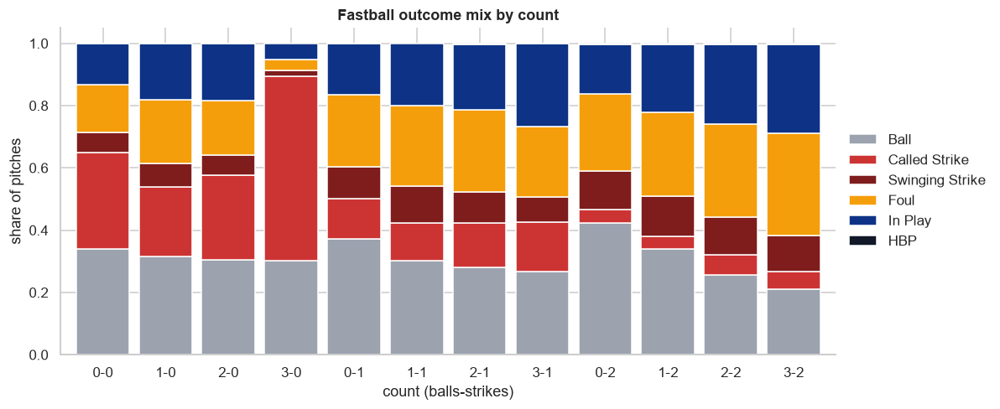

In [11]:
# ---- outcome mix by count (what a fastball does in each count) ----
order = ["0-0","1-0","2-0","3-0","0-1","1-1","2-1","3-1","0-2","1-2","2-2","3-2"]
mix = (df.groupby("count").result.value_counts(normalize=True).unstack().reindex(order)
         [["Ball","Called Strike","Swinging Strike","Foul","In Play","HBP"]])
ax = mix.plot(kind="bar", stacked=True, figsize=(11, 4.6), color=[OUTCOME_COLORS[c] for c in mix.columns], width=.85)
ax.set_title("Fastball outcome mix by count"); ax.set_ylabel("share of pitches"); ax.set_xlabel("count (balls-strikes)")
ax.legend(loc="center left", bbox_to_anchor=(1, .5), frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3 · Baseball visuals (static)

Reusable helpers that draw the **strike zone (catcher's view)** and a **ballpark diagram**, then use them for location surfaces, spray charts, movement profiles, release points and a one-call **pitcher card**.

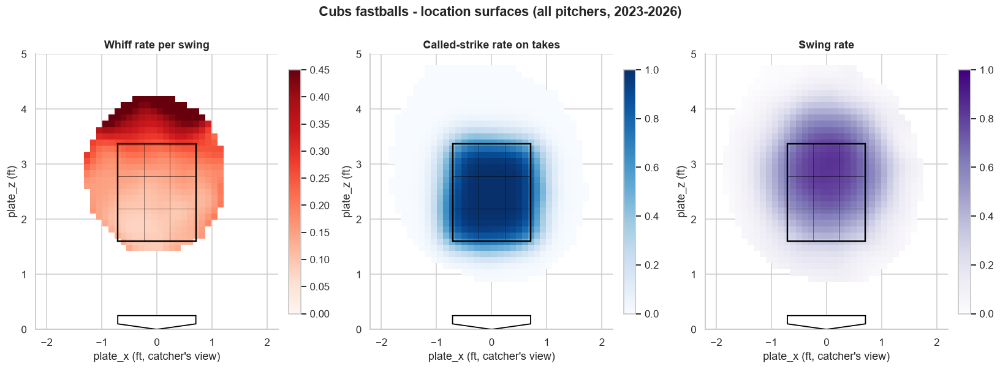

In [12]:
PLATE_HALF = 17 / 24          # half plate width in feet (8.5 in)
SZ_BOT, SZ_TOP = df.sz_bot.mean(), df.sz_top.mean()

def draw_zone(ax, color="black", lw=1.6, plate=True, inner=True):
    # strike zone box + home plate, catcher's perspective (x>0 = catcher's right / 1B side)
    ax.add_patch(Rectangle((-PLATE_HALF, SZ_BOT), 2 * PLATE_HALF, SZ_TOP - SZ_BOT, fill=False, ec=color, lw=lw, zorder=5))
    if inner:
        for f in (1/3, 2/3):
            ax.plot([-PLATE_HALF + 2*PLATE_HALF*f]*2, [SZ_BOT, SZ_TOP], color=color, lw=.6, alpha=.5, zorder=5)
            ax.plot([-PLATE_HALF, PLATE_HALF], [SZ_BOT + (SZ_TOP-SZ_BOT)*f]*2, color=color, lw=.6, alpha=.5, zorder=5)
    if plate:
        ax.add_patch(Polygon([(-PLATE_HALF, .25), (PLATE_HALF, .25), (PLATE_HALF, .1), (0, 0), (-PLATE_HALF, .1)],
                             closed=True, fc="white", ec=color, lw=1.2, zorder=5))
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(0, 5); ax.set_aspect("equal")

def rate_surface(x, y, num, den_mask, bins=(40, 40), rng_xy=((-2.2, 2.2), (0.3, 4.8)), sigma=1.5, min_n=4.0):
    # Smoothed 2-D rate: gaussian-smoothed successes / smoothed attempts, blanked where data is thin.
    m = den_mask.values
    H_den, xe, ye = np.histogram2d(x[m], y[m], bins=bins, range=rng_xy)
    H_num, _, _ = np.histogram2d(x[m][num[m].values], y[m][num[m].values], bins=bins, range=rng_xy)
    d, n = gaussian_filter(H_den, sigma), gaussian_filter(H_num, sigma)
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.where(d > min_n * (sigma**2 / 2.5), n / d, np.nan)
    return r.T, xe, ye

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
panels = [
    ("Whiff rate per swing", df.is_whiff, df.is_swing, "Reds", (0.0, 0.45)),
    ("Called-strike rate on takes", df.is_called_strike, df.is_take, "Blues", (0.0, 1.0)),
    ("Swing rate", df.is_swing, pd.Series(True, index=df.index), "Purples", (0.0, 1.0)),
]
for ax, (title, num, den, cmap, (vmin, vmax)) in zip(axes, panels):
    r, xe, ye = rate_surface(df.plate_x, df.plate_z, num, den)
    im = ax.pcolormesh(xe, ye, r, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    draw_zone(ax); ax.set_title(title); ax.set_xlabel("plate_x (ft, catcher's view)"); ax.set_ylabel("plate_z (ft)")
    plt.colorbar(im, ax=ax, fraction=.046, pad=.04)
fig.suptitle("Cubs fastballs - location surfaces (all pitchers, 2023-2026)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

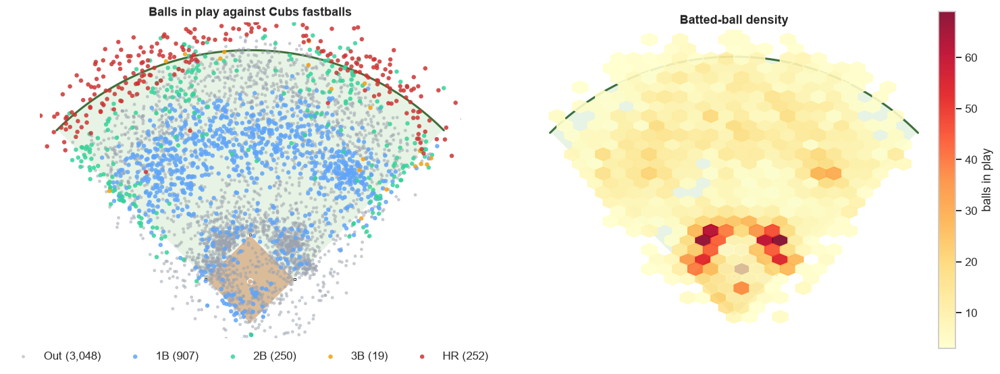

In [13]:
def draw_field(ax, wall_ft=390, lw=1.2):
    # Simple ballpark diagram in feet; home plate at the origin, +y toward CF, +x toward RF.
    th = np.radians(np.linspace(-45, 45, 200))
    ax.fill(np.r_[0, wall_ft*np.sin(th), 0], np.r_[0, wall_ft*np.cos(th), 0], color="#e7f3e4", zorder=0)
    ax.plot(wall_ft*np.sin(th), wall_ft*np.cos(th), color="#3f6f3a", lw=2)
    for s in (-1, 1):
        ax.plot([0, s*wall_ft*np.sin(np.radians(45))], [0, wall_ft*np.cos(np.radians(45))], color="white", lw=2, zorder=1)
    b = 90 / np.sqrt(2)
    ax.add_patch(Polygon([(0,0),(b,b),(0,2*b),(-b,b)], closed=True, fc="#d9b38c", ec="white", lw=lw, zorder=1, alpha=.85))
    ax.add_patch(Wedge((0, 60.5), 95, 0, 360, fc="#e7f3e4", ec="none", zorder=1.1, alpha=.0))
    for (bx, by) in [(b,b),(0,2*b),(-b,b)]:
        ax.add_patch(Rectangle((bx-1.3, by-1.3), 2.6, 2.6, fc="white", ec="k", lw=.6, zorder=3))
    ax.add_patch(Circle((0, 60.5), 4, fc="#d9b38c", ec="white", zorder=2))
    ax.set_xlim(-300, 300); ax.set_ylim(-20, 430); ax.set_aspect("equal"); ax.axis("off")

bip = df[df.is_bip & df.spray_x.notna()].copy()
bip["ev_class"] = bip.ev_group.replace({"ROE": "Out", "HBP": "Out"})
EV_COL = {"Out": "#9ca3af", "1B": "#60a5fa", "2B": "#34d399", "3B": "#f59e0b", "HR": "#CC3433"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
draw_field(axes[0])
for ev in ["Out", "1B", "2B", "3B", "HR"]:
    s = bip[bip.ev_class == ev]
    axes[0].scatter(s.spray_x, s.spray_y, s=10 if ev == "Out" else 18, c=EV_COL[ev], alpha=.55 if ev == "Out" else .85,
                    label=f"{ev} ({len(s):,})", zorder=4, edgecolor="none")
axes[0].legend(loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(.5, -.01)); axes[0].set_title("Balls in play against Cubs fastballs")
draw_field(axes[1])
hb = axes[1].hexbin(bip.spray_x, bip.spray_y, gridsize=26, cmap="YlOrRd", mincnt=3, extent=(-300, 300, 0, 430), zorder=4, alpha=.9)
plt.colorbar(hb, ax=axes[1], fraction=.04, pad=.01, label="balls in play"); axes[1].set_title("Batted-ball density")
plt.tight_layout(); plt.show()

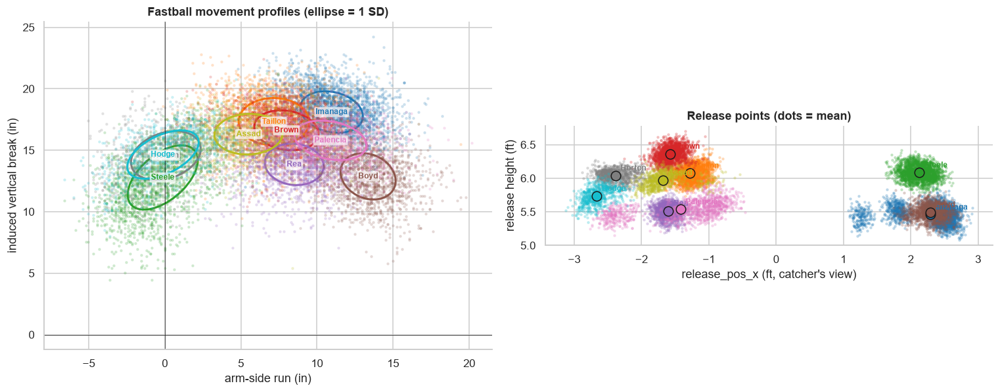

In [14]:
# ---- movement profiles (pitcher's view): arm-side run vs induced vertical break ----
top = pitcher_tbl.sort_values("pitches", ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
palette = sns.color_palette("tab10", len(top))
for col, (_, p) in zip(palette, top.iterrows()):
    g = df[df.pitcher == p.pitcher]
    axes[0].scatter(g.armside_in, g.ivb_in, s=4, color=col, alpha=.15)
    mu = g[["armside_in", "ivb_in"]].mean().values; cov = np.cov(g[["armside_in", "ivb_in"]].dropna().T)
    w, v = np.linalg.eigh(cov); ang = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
    axes[0].add_patch(Ellipse(mu, 2*np.sqrt(w[1]), 2*np.sqrt(w[0]), angle=ang, fc="none", ec=col, lw=2))
    axes[0].annotate(p.pitcher_name.split()[-1], mu, fontsize=8, fontweight="bold", color=col, ha="center", va="center",
                     bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.7))
axes[0].axhline(0, color="k", lw=.5); axes[0].axvline(0, color="k", lw=.5)
axes[0].set_xlabel("arm-side run (in)"); axes[0].set_ylabel("induced vertical break (in)")
axes[0].set_title("Fastball movement profiles (ellipse = 1 SD)")

# ---- release points: catcher's view ----
for col, (_, p) in zip(palette, top.iterrows()):
    g = df[df.pitcher == p.pitcher]
    axes[1].scatter(g.release_pos_x, g.release_pos_z, s=4, color=col, alpha=.2)
    axes[1].scatter(g.release_pos_x.mean(), g.release_pos_z.mean(), s=90, color=col, ec="k", zorder=3)
    axes[1].annotate(p.pitcher_name.split()[-1], (g.release_pos_x.mean(), g.release_pos_z.mean()), xytext=(5, 5),
                     textcoords="offset points", fontsize=8, color=col, fontweight="bold")
axes[1].set_xlabel("release_pos_x (ft, catcher's view)"); axes[1].set_ylabel("release height (ft)")
axes[1].set_title("Release points (dots = mean)"); axes[1].set_aspect("equal")
plt.tight_layout(); plt.show()

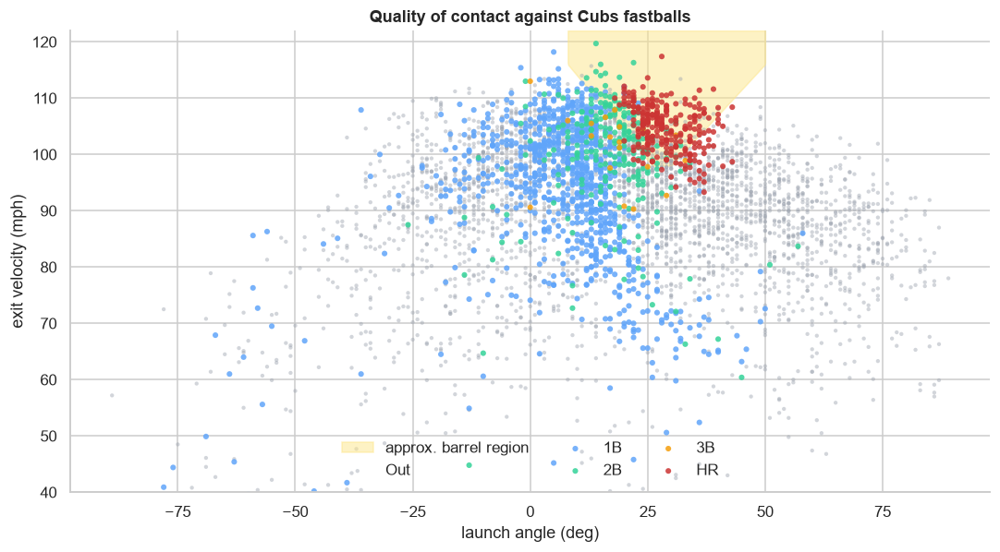

In [15]:
# ---- exit velocity vs launch angle, the "Statcast sweet-spot" view ----
b2 = df[df.is_bip & df.launch_speed.notna() & df.launch_angle.notna()].copy()
b2["ev_class"] = b2.ev_group.replace({"ROE": "Out", "HBP": "Out"})
fig, ax = plt.subplots(figsize=(10, 5.6))
ev_grid = np.linspace(98, 122, 60)       # Statcast barrel: >=98 mph, angle band widens ~1 deg/mph (approximation)
lo = np.clip(26 - (ev_grid - 98), 8, None); hi = np.clip(30 + (ev_grid - 98) * 1.11, None, 50)
ax.fill_betweenx(ev_grid, lo, hi, color="#fde68a", alpha=.5, label="approx. barrel region")
for ev in ["Out", "1B", "2B", "3B", "HR"]:
    s = b2[b2.ev_class == ev]
    ax.scatter(s.launch_angle, s.launch_speed, s=8 if ev == "Out" else 16, c=EV_COL[ev], alpha=.45 if ev == "Out" else .85, label=ev, edgecolor="none")
ax.set_xlabel("launch angle (deg)"); ax.set_ylabel("exit velocity (mph)"); ax.set_ylim(40, 122)
ax.set_title("Quality of contact against Cubs fastballs"); ax.legend(ncol=3, frameon=False, loc="lower center")
plt.tight_layout(); plt.show()

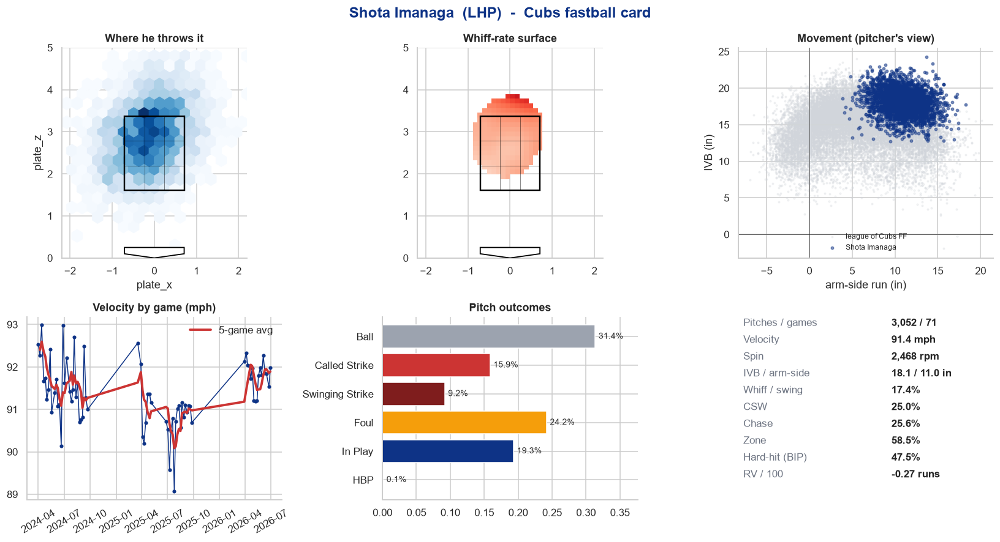

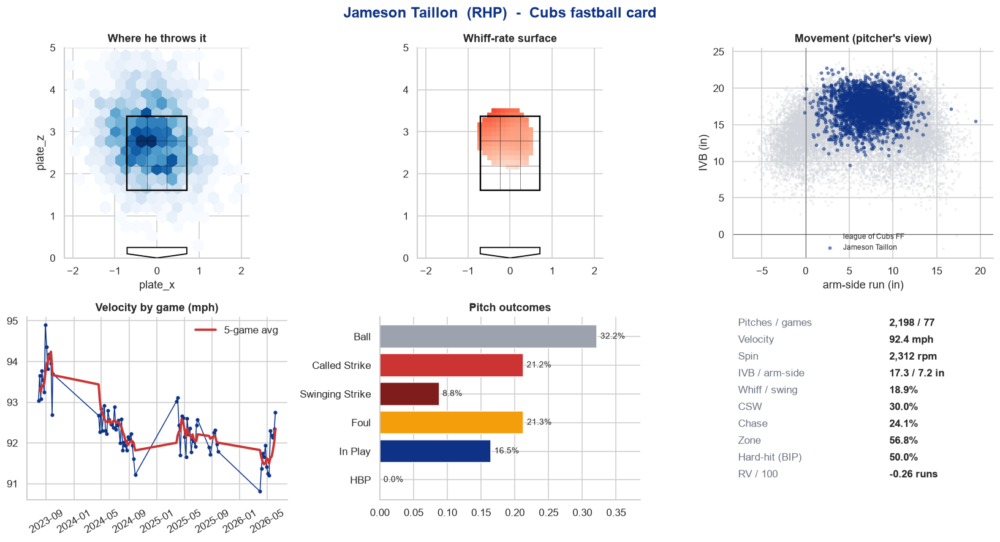

In [16]:
def pitcher_card(pid, data=None):
    # One-call pitcher report card: location heat, movement, velocity by game, outcome mix, key metrics.
    d = (data if data is not None else df)
    g = d[d.pitcher == pid]
    name, hand = g.pitcher_name.iloc[0], g.p_throws.iloc[0]
    m = pitch_metrics(g)
    fig = plt.figure(figsize=(15, 8.2)); gs = fig.add_gridspec(2, 3, height_ratios=[1.15, 1])
    ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])
    ax4, ax5, ax6 = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 2])

    h = ax1.hexbin(g.plate_x, g.plate_z, gridsize=18, extent=(-2.2, 2.2, 0.3, 4.8), cmap="Blues", mincnt=1)
    draw_zone(ax1); ax1.set_title("Where he throws it"); ax1.set_xlabel("plate_x"); ax1.set_ylabel("plate_z")

    r, xe, ye = rate_surface(g.plate_x, g.plate_z, g.is_whiff, g.is_swing, sigma=2.2, min_n=1.5)
    ax2.pcolormesh(xe, ye, r, cmap="Reds", vmin=0, vmax=.5, shading="auto"); draw_zone(ax2); ax2.set_title("Whiff-rate surface")

    ax3.scatter(d.armside_in, d.ivb_in, s=3, color="#d1d5db", alpha=.25, label="league of Cubs FF")
    ax3.scatter(g.armside_in, g.ivb_in, s=8, color=CUBS_BLUE, alpha=.5, label=name)
    ax3.axhline(0, color="k", lw=.4); ax3.axvline(0, color="k", lw=.4); ax3.legend(frameon=False, fontsize=8)
    ax3.set_title("Movement (pitcher's view)"); ax3.set_xlabel("arm-side run (in)"); ax3.set_ylabel("IVB (in)")

    gm = g.groupby("game_date").release_speed.agg(["mean", "size"]).query("size >= 5")
    ax4.plot(gm.index, gm["mean"], "o-", color=CUBS_BLUE, ms=3, lw=1)
    ax4.plot(gm.index, gm["mean"].rolling(5, min_periods=2).mean(), color=CUBS_RED, lw=2.5, label="5-game avg")
    ax4.set_title("Velocity by game (mph)"); ax4.legend(frameon=False); ax4.tick_params(axis="x", rotation=30)

    res = g.result.value_counts(normalize=True).reindex(OUTCOME_COLORS.keys()).fillna(0)
    ax5.barh(res.index[::-1], res.values[::-1], color=[OUTCOME_COLORS[k] for k in res.index[::-1]])
    for i, v in enumerate(res.values[::-1]): ax5.text(v + .005, i, f"{v:.1%}", va="center", fontsize=9)
    ax5.set_title("Pitch outcomes"); ax5.set_xlim(0, res.max() * 1.2)

    ax6.axis("off")
    rows = [("Pitches / games", f"{int(m.pitches):,} / {int(m.games)}"), ("Velocity", f"{m.velo:.1f} mph"),
            ("Spin", f"{m.spin:,.0f} rpm"), ("IVB / arm-side", f"{m.ivb_in:.1f} / {m.armside_in:.1f} in"),
            ("Whiff / swing", f"{m['whiff/swing_%']:.1f}%"), ("CSW", f"{m['CSW_%']:.1f}%"),
            ("Chase", f"{m['chase_%']:.1f}%"), ("Zone", f"{m['zone_%']:.1f}%"),
            ("Hard-hit (BIP)", f"{m['hardhit_%']:.1f}%"), ("RV / 100", f"{m['RV/100']:+.2f} runs")]
    for i, (k, v) in enumerate(rows):
        ax6.text(0.02, 0.95 - i * 0.092, k, fontsize=11, color=GREY, transform=ax6.transAxes)
        ax6.text(0.60, 0.95 - i * 0.092, v, fontsize=11, fontweight="bold", transform=ax6.transAxes)
    fig.suptitle(f"{name}  ({hand}HP)  -  Cubs fastball card", fontsize=16, fontweight="bold", color=CUBS_BLUE)
    plt.tight_layout(); plt.show()

# Show cards for the two most-used pitchers (call pitcher_card(<mlbam id>) for anyone)
for pid in pitcher_tbl.sort_values("pitches", ascending=False).pitcher.head(2):
    pitcher_card(pid)

## 4 · Interactive visuals (Plotly)

Everything below is interactive: hover for details, click legend entries to isolate groups, use the dropdowns, drag to zoom, and rotate the 3-D plot. Each figure is also exported as a standalone HTML file in `cubs_outputs/figures/`.

In [18]:
# ---- 4.1 Strike-zone explorer: choose a pitcher, hover any pitch, click legend to filter outcomes ----
df["hover"] = ("<b>" + df.batter_name + "</b> (" + df.stand + "HB)<br>" + df.game_date.dt.strftime("%Y-%m-%d")
               + " vs " + df.opp + "<br>" + df.release_speed.round(1).astype(str) + " mph, count " + df["count"]
               + "<br>" + df.result + np.where(df.ev_group.notna(), " - " + df.ev_group.fillna(""), ""))

top12 = pitcher_tbl.sort_values("pitches", ascending=False).head(12)
groups = [("All Cubs pitchers", df.sample(3000, random_state=SEED))]
groups += [(r.pitcher_name, df[df.pitcher == r.pitcher].sample(min(900, int(r.pitches)), random_state=SEED)) for r in top12.itertuples()]

fig = go.Figure(); owner = []
for gi, (label, gs) in enumerate(groups):
    for o in OUTCOME_COLORS:
        s = gs[gs.result == o]
        fig.add_trace(go.Scatter(x=s.plate_x, y=s.plate_z, mode="markers", name=o, legendgroup=o, text=s.hover,
                                 hovertemplate="%{text}<extra></extra>", visible=(gi == 0),
                                 marker=dict(size=7, color=OUTCOME_COLORS[o], opacity=.65, line=dict(width=0))))
        owner.append(gi)
owner = np.array(owner)
buttons = [dict(label=lbl, method="update",
                args=[{"visible": (owner == i).tolist()}, {"title": f"Pitch locations - {lbl} (catcher's view)"}])
           for i, (lbl, _) in enumerate(groups)]
ph = PLATE_HALF
fig.update_layout(
    title="Pitch locations - All Cubs pitchers (catcher's view)", height=640, width=760,
    xaxis=dict(range=[-2.6, 2.6], title="plate_x (ft)", scaleanchor="y", zeroline=False),
    yaxis=dict(range=[0, 5.2], title="plate_z (ft)", zeroline=False),
    updatemenus=[dict(buttons=buttons, direction="down", x=0.0, y=1.14, xanchor="left", yanchor="top")],
    shapes=[dict(type="rect", x0=-ph, x1=ph, y0=SZ_BOT, y1=SZ_TOP, line=dict(color="black", width=2)),
            dict(type="path", path=f"M {-ph},0.25 L {ph},0.25 L {ph},0.1 L 0,0 L {-ph},0.1 Z", line=dict(color="black", width=1.5), fillcolor="white")],
    legend=dict(orientation="h", y=-0.12))
save_fig(fig, "pitcher_strikezone")
fig.show()

In [19]:
# ---- 4.2 Interactive spray chart ----
def field_shapes(wall=390):
    th = np.radians(np.linspace(-45, 45, 60))
    arc = " ".join(f"L {wall*np.sin(t):.1f},{wall*np.cos(t):.1f}" for t in th)
    b = 90 / np.sqrt(2)
    return [
        dict(type="path", path=f"M 0,0 {arc} Z", fillcolor="rgba(231,243,228,1)", line=dict(color="#3f6f3a", width=2), layer="below"),
        dict(type="path", path=f"M 0,0 L {b},{b} L 0,{2*b} L {-b},{b} Z", fillcolor="rgba(217,179,140,.85)", line=dict(color="white", width=1), layer="below"),
        dict(type="line", x0=0, y0=0, x1=wall*np.sin(np.radians(45)), y1=wall*np.cos(np.radians(45)), line=dict(color="white", width=2), layer="below"),
        dict(type="line", x0=0, y0=0, x1=-wall*np.sin(np.radians(45)), y1=wall*np.cos(np.radians(45)), line=dict(color="white", width=2), layer="below"),
    ]

sp = bip.copy()
sp["tip"] = ("<b>" + sp.batter_name + "</b> vs " + sp.pitcher_name + "<br>" + sp.game_date.dt.strftime("%Y-%m-%d")
             + "<br>EV " + sp.launch_speed.round(0).astype("Int64").astype(str) + " mph, LA " + sp.launch_angle.round(0).astype("Int64").astype(str)
             + "&deg;<br>Distance " + sp.hit_distance_sc.round(0).astype("Int64").astype(str) + " ft<br><b>" + sp.ev_class + "</b>")
fig = go.Figure()
for ev in ["Out", "1B", "2B", "3B", "HR"]:
    s = sp[sp.ev_class == ev]
    fig.add_trace(go.Scatter(x=s.spray_x, y=s.spray_y, mode="markers", name=f"{ev} ({len(s):,})", text=s.tip,
                             hovertemplate="%{text}<extra></extra>",
                             marker=dict(size=6 if ev == "Out" else 9, color=EV_COL[ev], opacity=.5 if ev == "Out" else .9)))
fig.update_layout(title="Spray chart - balls in play vs Cubs fastballs (click legend to isolate)", height=680, width=820,
                  xaxis=dict(range=[-300, 300], visible=False, scaleanchor="y"), yaxis=dict(range=[-20, 430], visible=False),
                  shapes=field_shapes(), plot_bgcolor="white")
save_fig(fig, "spraychart")
fig.show()

In [20]:
# ---- 4.3 Animated 3-D pitch trajectories (rotate, zoom, press Play) ----
# Physics: constant-acceleration trajectory from Statcast vx0/vy0/vz0 and ax/ay/az (measured at y=50 ft).
# The path is calibrated so each pitch lands exactly on the recorded plate_x / plate_z.
PLATE_FRONT = 17 / 12

def build_trajectories(g, n_pts=36):
    a, b, c = 0.5 * g.ay.values, g.vy0.values, 50 - PLATE_FRONT
    t_end = (-b - np.sqrt(b**2 - 4 * a * c)) / (2 * a)
    T = np.linspace(0, 1, n_pts)[None, :] * t_end[:, None]
    X = g.release_pos_x.values[:, None] + g.vx0.values[:, None] * T + 0.5 * g.ax.values[:, None] * T**2
    Z = g.release_pos_z.values[:, None] + g.vz0.values[:, None] * T + 0.5 * g.az.values[:, None] * T**2
    Y = 50 + g.vy0.values[:, None] * T + 0.5 * g.ay.values[:, None] * T**2
    frac = T / t_end[:, None]
    X = X + (g.plate_x.values[:, None] - X[:, [-1]]) * frac
    Z = Z + (g.plate_z.values[:, None] - Z[:, [-1]]) * frac
    return X, Y, Z, t_end

traj_cols = ["vx0", "vy0", "vz0", "ax", "ay", "az", "release_pos_x", "release_pos_z", "plate_x", "plate_z"]
star = pitcher_tbl.sort_values("pitches", ascending=False).iloc[0]
cand = df[(df.pitcher == star.pitcher)].dropna(subset=traj_cols)
samp = pd.concat([cand[cand.result == o].sample(min(7, (cand.result == o).sum()), random_state=SEED) for o in OUTCOME_COLORS if o != "HBP"])
X, Y, Z, t_end = build_trajectories(samp)
cols = samp.result.map(OUTCOME_COLORS).tolist()
n_pts = X.shape[1]

fig = go.Figure()
# trace 0 = moving baseballs (updated by frames); then faint full paths; then zone + plate
fig.add_trace(go.Scatter3d(x=X[:, 0], y=Y[:, 0], z=Z[:, 0], mode="markers", name="pitch",
                           marker=dict(size=5, color=cols, line=dict(color="black", width=1)),
                           text=samp.result + " - " + samp.release_speed.round(1).astype(str) + " mph", hoverinfo="text"))
for i in range(len(samp)):
    fig.add_trace(go.Scatter3d(x=X[i], y=Y[i], z=Z[i], mode="lines", line=dict(color=cols[i], width=2), opacity=.35,
                               showlegend=False, hoverinfo="skip"))
zx = [-PLATE_HALF, PLATE_HALF, PLATE_HALF, -PLATE_HALF, -PLATE_HALF]; zz = [SZ_BOT, SZ_BOT, SZ_TOP, SZ_TOP, SZ_BOT]
fig.add_trace(go.Scatter3d(x=zx, y=[PLATE_FRONT]*5, z=zz, mode="lines", line=dict(color="black", width=6), name="strike zone"))
fig.add_trace(go.Scatter3d(x=[-PLATE_HALF, PLATE_HALF, PLATE_HALF, 0, -PLATE_HALF, -PLATE_HALF], y=[1.4, 1.4, .7, 0, .7, 1.4],
                           z=[0]*6, mode="lines", line=dict(color="black", width=5), name="plate"))
fig.frames = [go.Frame(data=[go.Scatter3d(x=X[:, k], y=Y[:, k], z=Z[:, k])], traces=[0], name=str(k)) for k in range(n_pts)]
fig.update_layout(
    title=f"{star.pitcher_name} - 42 fastballs in 3-D (colour = outcome)", height=640,
    scene=dict(xaxis=dict(title="x (ft)", range=[-4, 4]), yaxis=dict(title="distance to plate (ft)", range=[55, 0]),
               zaxis=dict(title="height (ft)", range=[0, 8]), aspectmode="manual", aspectratio=dict(x=.8, y=3.2, z=1),
               camera=dict(eye=dict(x=1.7, y=1.9, z=.7))),
    updatemenus=[dict(type="buttons", showactive=False, x=.02, y=.02, buttons=[
        dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=45, redraw=True), fromcurrent=True)]),
        dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0), mode="immediate")])])],
    sliders=[dict(steps=[dict(method="animate", label="", args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for k in range(n_pts)],
                  x=.15, len=.8, currentvalue=dict(visible=False))])
save_fig(fig, "pitch_trajectory")
fig.show()

print(f"Average ball flight time (y=50 ft to plate front): {t_end.mean():.3f} s")

Average ball flight time (y=50 ft to plate front): 0.381 s


In [21]:
# ---- 4.4 Pitcher dashboard: choose ANY two metrics for the axes ----
pt = pitcher_tbl.copy()
pt["label"] = pt.pitcher_name
metrics = {"Velocity (mph)": "velo", "Spin (rpm)": "spin", "IVB (in)": "ivb_in", "Arm-side run (in)": "armside_in",
           "Extension (ft)": "ext_ft", "Zone %": "zone_%", "Whiff / swing %": "whiff/swing_%", "Chase %": "chase_%",
           "CSW %": "CSW_%", "Hard-hit %": "hardhit_%", "xwOBA on contact": "xwOBAcon", "Run value / 100": "RV/100"}
fig = go.Figure(go.Scatter(
    x=pt["velo"], y=pt["CSW_%"], mode="markers+text", text=pt.pitcher_name.str.split().str[-1], textposition="top center",
    textfont=dict(size=9), marker=dict(size=np.sqrt(pt.pitches) * 1.3, color=pt["RV/100"], colorscale="RdBu", cmid=0,
                                      colorbar=dict(title="RV/100"), line=dict(width=1, color="white")),
    customdata=np.c_[pt.pitcher_name, pt.pitches, pt["RV/100"].round(2)],
    hovertemplate="<b>%{customdata[0]}</b><br>%{customdata[1]} pitches<br>RV/100 %{customdata[2]}<extra></extra>"))
xb = [dict(label=k, method="update", args=[{"x": [pt[v]]}, {"xaxis.title.text": k}]) for k, v in metrics.items()]
yb = [dict(label=k, method="update", args=[{"y": [pt[v]]}, {"yaxis.title.text": k}]) for k, v in metrics.items()]
fig.update_layout(title="Cubs pitchers - pick your axes (bubble = pitches, colour = run value per 100)", height=620,
                  xaxis_title="Velocity (mph)", yaxis_title="CSW %",
                  updatemenus=[dict(buttons=xb, x=0.0, y=1.17, xanchor="left", active=0, showactive=True),
                               dict(buttons=yb, x=0.45, y=1.17, xanchor="left", active=8, showactive=True)],
                  annotations=[dict(text="X axis:", x=0, y=1.21, xref="paper", yref="paper", showarrow=False),
                               dict(text="Y axis:", x=0.45, y=1.21, xref="paper", yref="paper", showarrow=False)])
fig.show() #save_fig(fig, "pitcher_dashboard")

In [22]:
# ---- 4.5 Velocity tracker: rolling game-by-game velocity per pitcher (range slider + dropdown) ----
trk = pitcher_tbl.sort_values("pitches", ascending=False).head(15)
fig = go.Figure()
for i, r in enumerate(trk.itertuples()):
    gm = (df[df.pitcher == r.pitcher].groupby("game_date").release_speed.agg(["mean", "size"]).query("size >= 5"))
    fig.add_trace(go.Scatter(x=gm.index, y=gm["mean"], mode="markers", name="game avg", marker=dict(color=CUBS_BLUE, size=6, opacity=.55),
                             visible=(i == 0), hovertemplate="%{x|%Y-%m-%d}<br>%{y:.1f} mph<extra></extra>"))
    fig.add_trace(go.Scatter(x=gm.index, y=gm["mean"].rolling(5, min_periods=2).mean(), mode="lines", name="5-game avg",
                             line=dict(color=CUBS_RED, width=3), visible=(i == 0)))
btn = [dict(label=r.pitcher_name, method="update", args=[{"visible": [j // 2 == i for j in range(2 * len(trk))]},
                                                          {"title": f"{r.pitcher_name} - game-average fastball velocity"}])
       for i, r in enumerate(trk.itertuples())]
fig.update_layout(title=f"{trk.iloc[0].pitcher_name} - game-average fastball velocity", height=470, yaxis_title="mph",
                  updatemenus=[dict(buttons=btn, x=0, y=1.2, xanchor="left")],
                  xaxis=dict(rangeslider=dict(visible=True), rangeselector=dict(buttons=[
                      dict(count=1, label="1m", step="month", stepmode="backward"), dict(count=6, label="6m", step="month", stepmode="backward"),
                      dict(step="all")])))
fig.show() #save_fig(fig, "velocity_tracker")

In [55]:
# ---- 4.6 Sunburst: season -> batter side -> pitch result (click to drill down) ----
sb = df.assign(batter_side=df.stand.map({"L": "vs LHB", "R": "vs RHB"}), season=df.season.astype(str))
sb = sb.groupby(["season", "batter_side", "result"]).size().reset_index(name="pitches")
fig = px.sunburst(sb, path=["season", "batter_side", "result"], values="pitches", color="result",
                  color_discrete_map={**OUTCOME_COLORS, "(?)": "#e5e7eb"}, title="Where do the fastballs go? (click a slice)")
fig.update_layout(height=620); fig.show()

# ---- 4.7 Opponent explorer: switch the metric ----
opp = df.groupby("opp").apply(lambda g: pd.Series({
    "pitches": len(g), "Whiff / swing %": g[g.is_swing].is_whiff.mean() * 100, "CSW %": g.is_csw.mean() * 100,
    "Chase %": g[~g.in_zone].is_swing.mean() * 100, "Hard-hit %": (g[g.is_bip].launch_speed >= 95).mean() * 100,
    "Run value / 100": g.rv_pitcher.mean() * 100})).reset_index()
metric_names = ["Whiff / swing %", "CSW %", "Chase %", "Hard-hit %", "Run value / 100"]
fig = go.Figure(go.Bar(x=opp.sort_values(metric_names[0], ascending=False).opp, y=opp.sort_values(metric_names[0], ascending=False)[metric_names[0]], marker_color=CUBS_BLUE))
btn = []
for m in metric_names:
    o = opp.sort_values(m, ascending=False)
    btn.append(dict(label=m, method="update", args=[{"x": [o.opp], "y": [o[m]]}, {"title": f"{m} by opponent (Cubs fastballs)"}]))
fig.update_layout(title=f"{metric_names[0]} by opponent (Cubs fastballs)", height=430, updatemenus=[dict(buttons=btn, x=0, y=1.2, xanchor="left")])
fig.update_yaxes(title=None); 
save_fig(fig, "sunburst")
fig.show()

## 5 · Statistical models

Classical, interpretable models: run values, an **absorbing Markov chain** for the ball-strike count, regression with cluster-robust inference, hypothesis tests with effect sizes, a cluster bootstrap, and a mixed-effects fatigue model.

### 5.1 Run value of each pitch result and count

,RV per pitch,pitches,RV per 100
result,,,
HBP,-0.333,44,-33.311
Ball,-0.062,8105,-6.235
In Play,-0.049,4477,-4.866
Foul,0.035,5461,3.534
Called Strike,0.064,4616,6.393
Swinging Strike,0.115,2297,11.459


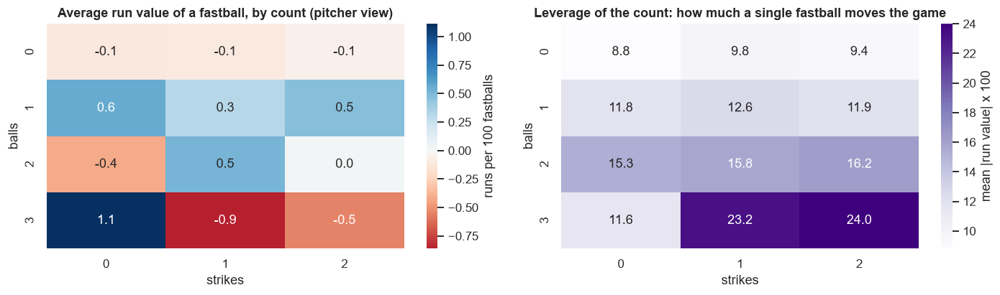

In [24]:
rv_res = (df.groupby("result").rv_pitcher.agg(["mean", "count"]).rename(columns={"mean": "RV per pitch", "count": "pitches"})
            .assign(**{"RV per 100": lambda d: d["RV per pitch"] * 100}).sort_values("RV per pitch"))
display(rv_res.round(3))

rv_cnt = df.groupby(["balls", "strikes"]).rv_pitcher.mean().unstack() * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
sns.heatmap(rv_cnt, annot=True, fmt=".1f", cmap="RdBu", center=0, ax=axes[0], cbar_kws={"label": "runs per 100 fastballs"})
axes[0].set_title("Average run value of a fastball, by count (pitcher view)"); axes[0].set_xlabel("strikes"); axes[0].set_ylabel("balls")
vol = df.groupby(["balls", "strikes"]).rv_pitcher.apply(lambda s: s.abs().mean() * 100).unstack()
sns.heatmap(vol, annot=True, fmt=".1f", cmap="Purples", ax=axes[1], cbar_kws={"label": "mean |run value| x 100"})
axes[1].set_title("Leverage of the count: how much a single fastball moves the game"); axes[1].set_xlabel("strikes"); axes[1].set_ylabel("balls")
plt.tight_layout(); plt.show()

### 5.2 The count as an absorbing Markov chain

The 12 ball-strike counts are *transient* states. A plate appearance is absorbed by one of four outcomes: **strikeout, walk, hit-by-pitch, ball in play**. From pitch-outcome frequencies in each count we build the substochastic matrix **Q** (count → count) and absorption matrix **R** (count → outcome), then use the fundamental matrix $N=(I-Q)^{-1}$:

- $N_{ij}$ = expected visits to count *j* starting from count *i*
- $B = NR$ = probability of each plate-appearance ending
- $N\mathbf 1$ = expected number of pitches remaining

> Because the data only contains **fastballs**, this chain answers: *"what would a plate appearance look like if every pitch were a Cubs 4-seamer?"* It is a model of the fastball, not of a full at-bat.

In [25]:
COUNTS = [(b, s) for s in range(3) for b in range(4)]            # 12 transient states
CIDX = {c: i for i, c in enumerate(COUNTS)}
CLOOK = np.zeros((4, 3), dtype=int)
for (b, s), i in CIDX.items(): CLOOK[b, s] = i
POUTS = ["Ball", "Called Strike", "Swinging Strike", "Foul", "In Play", "HBP"]
TERMS = ["K", "BB", "HBP", "In play"]
COUNT_LABELS = [f"{b}-{s}" for b, s in COUNTS]

def count_prob_matrix(d, alpha=0.5):
    # empirical P(pitch result | count), rows ordered as COUNTS, with a small Dirichlet smoother
    ct = pd.crosstab(d["count"], d["result"]).reindex(COUNT_LABELS).reindex(columns=POUTS).fillna(0) + alpha
    return (ct.div(ct.sum(1), axis=0)).values

def chain_matrices(P):
    # P: (12, 6) pitch-result probabilities -> Q (12x12 transient), R (12x4 absorbing)
    Q, R = np.zeros((12, 12)), np.zeros((12, 4))
    for (b, s), i in CIDX.items():
        pB, pCS, pSS, pF, pIP, pH = P[i]
        if b == 3: R[i, 1] += pB
        else:      Q[i, CIDX[(b + 1, s)]] += pB
        for p in (pCS, pSS):
            if s == 2: R[i, 0] += p
            else:      Q[i, CIDX[(b, s + 1)]] += p
        Q[i, CIDX[(b, min(s + 1, 2))]] += pF                   # foul: strike unless already 2
        R[i, 3] += pIP; R[i, 2] += pH
    return Q, R

def absorb(Q, R):
    N = np.linalg.inv(np.eye(12) - Q)
    return N, N @ R, N.sum(1)

P_lg = count_prob_matrix(df)
Q, R = chain_matrices(P_lg)
N, B, pitches_left = absorb(Q, R)
assert np.allclose(Q.sum(1) + R.sum(1), 1), "rows must sum to one"

absorb_tbl = pd.DataFrame(B, index=COUNT_LABELS, columns=TERMS)
absorb_tbl["E[pitches left]"] = pitches_left
print("Fastball-only plate appearance starting at 0-0:")
print(absorb_tbl.loc["0-0"].round(3).to_dict())
show = absorb_tbl.loc[["0-0", "1-0", "0-1", "1-1", "0-2", "2-0", "3-2"]].copy()
show[TERMS] = show[TERMS] * 100
display(show.rename(columns={t: t + " %" for t in TERMS}).round(1))

Fastball-only plate appearance starting at 0-0:
{'K': 0.221, 'BB': 0.065, 'HBP': 0.008, 'In play': 0.707, 'E[pitches left]': 3.88}


,K %,BB %,HBP %,In play %,E[pitches left]
0-0,22.1,6.5,0.8,70.7,3.9
1-0,17.5,12.3,0.8,69.5,3.4
0-1,30.5,4.3,0.8,64.3,3.3
1-1,26.4,7.9,0.6,65.1,2.9
0-2,44.7,3.0,0.8,51.5,2.6
2-0,13.3,26.1,0.7,59.8,2.9
3-2,25.5,31.5,0.5,42.5,1.5


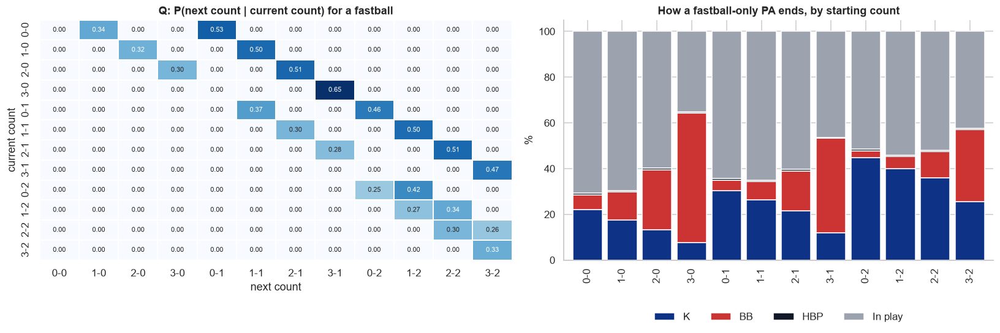

In [26]:
# ---- visual: transition matrix heatmap + outcome probabilities by starting count ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(pd.DataFrame(Q, index=COUNT_LABELS, columns=COUNT_LABELS), cmap="Blues", annot=True, fmt=".2f", annot_kws={"size": 7},
            ax=axes[0], cbar=False, linewidths=.3)
axes[0].set_title("Q: P(next count | current count) for a fastball"); axes[0].set_xlabel("next count"); axes[0].set_ylabel("current count")
(absorb_tbl[TERMS] * 100).plot(kind="bar", stacked=True, ax=axes[1], color=[CUBS_BLUE, CUBS_RED, "#111827", "#9ca3af"], width=.85)
axes[1].set_title("How a fastball-only PA ends, by starting count"); axes[1].set_ylabel("%"); axes[1].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.18))
plt.tight_layout(); plt.show()

# ---- Sankey: expected flow through the counts from 0-0 (2-strike foul self-loops omitted) ----
flow_src, flow_dst, flow_val = [], [], []
for i in range(12):
    visit = N[0, i]
    for j in range(12):
        if i != j and Q[i, j] > 0: flow_src.append(i); flow_dst.append(j); flow_val.append(visit * Q[i, j])
    for t in range(4):
        if R[i, t] > 0: flow_src.append(i); flow_dst.append(12 + t); flow_val.append(visit * R[i, t])
node_col = ["#cbd5e1"] * 12 + [CUBS_BLUE, CUBS_RED, "#111827", "#9ca3af"]
link_col = [("rgba(14,51,134,.25)" if d >= 12 and d - 12 == 0 else "rgba(204,52,51,.25)" if d == 13 else "rgba(150,150,150,.22)") for d in flow_dst]
fig = go.Figure(go.Sankey(node=dict(label=COUNT_LABELS + TERMS, color=node_col, pad=14, thickness=16),
                          link=dict(source=flow_src, target=flow_dst, value=flow_val, color=link_col)))
fig.update_layout(title="Expected flow of a fastball-only plate appearance through the count (from 0-0)", height=560)
fig.show() #save_fig(fig, "count_sankey")

In [27]:
# ---- Monte Carlo check of the analytic chain: simulate pitch-by-pitch and compare ----
def simulate_pa_mc(P, n, rng):
    b, s = np.zeros(n, int), np.zeros(n, int)
    alive, term, npitch = np.ones(n, bool), np.full(n, -1), np.zeros(n, int)
    cum = np.cumsum(P, axis=1)
    while alive.any():
        idx = np.where(alive)[0]
        ci = CLOOK[b[idx], s[idx]]
        o = np.minimum((rng.random(len(idx))[:, None] > cum[ci]).sum(1), 5)
        npitch[idx] += 1
        bi, si = b[idx], s[idx]
        ball, strike, foul, ip, hbp = (o == 0), (o == 1) | (o == 2), (o == 3), (o == 4), (o == 5)
        done = np.zeros(len(idx), bool); t = np.full(len(idx), -1)
        m = ball & (bi == 3);   t[m] = 1; done |= m
        m = strike & (si == 2); t[m] = 0; done |= m
        m = ip;  t[m] = 3; done |= m
        m = hbp; t[m] = 2; done |= m
        b[idx[ball & ~done]] += 1
        s[idx[(strike & ~done) | (foul & (si < 2))]] += 1
        term[idx[done]] = t[done]; alive[idx[done]] = False
    return term, npitch

term, npx = simulate_pa_mc(P_lg, 200_000, rng)
mc = np.bincount(term, minlength=4) / len(term)
cmp_tbl = pd.DataFrame({"analytic (Markov)": B[0], "Monte Carlo (200k PAs)": mc}, index=TERMS)
cmp_tbl.loc["E[pitches]"] = [pitches_left[0], npx.mean()]
display(cmp_tbl.round(4))

,analytic (Markov),Monte Carlo (200k PAs)
K,0.2206,0.2218
BB,0.0645,0.0642
HBP,0.0080,0.0080
In play,0.7069,0.7060
E[pitches],3.8805,3.8800


### 5.3 Regression: what makes a fastball miss bats?

A logistic regression for **whiff given a swing**, using standardised pitch characteristics (odds ratios are per +1 SD) plus location and context. Standard errors are **clustered by game** because pitches within a game are not independent.

In [28]:
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score

feat = ["release_speed", "release_spin_rate", "ivb_in", "armside_in", "release_extension"]
sw = df[df.is_swing].dropna(subset=feat + ["plate_x", "plate_z"]).copy()
sw["whiff"] = sw.is_whiff.astype(int)
for c in feat:
    sw[c + "_z"] = (sw[c] - sw[c].mean()) / sw[c].std()
sw["plate_z_c"] = sw.plate_z - 2.9
sw["abs_plate_x"] = sw.plate_x.abs()
sw["in_zone_i"] = sw.in_zone.astype(int)
sw["platoon_i"] = sw.platoon_adv.astype(int)

form = ("whiff ~ release_speed_z + release_spin_rate_z + ivb_in_z + armside_in_z + release_extension_z"
        " + plate_z_c + I(plate_z_c**2) + abs_plate_x + in_zone_i + platoon_i + C(strikes) + C(season)")
m_whiff = smf.logit(form, data=sw).fit(disp=0, cov_type="cluster", cov_kwds={"groups": sw.game_pk})
print(f"n swings = {len(sw):,}   pseudo-R2 = {m_whiff.prsquared:.3f}   AUC = {roc_auc_score(sw.whiff, m_whiff.predict(sw)):.3f}   base whiff rate = {sw.whiff.mean():.3f}")

coef = pd.DataFrame({"OR": np.exp(m_whiff.params), "lo": np.exp(m_whiff.conf_int()[0]), "hi": np.exp(m_whiff.conf_int()[1]), "p": m_whiff.pvalues})
coef = coef.drop(index="Intercept")
nice = {"release_speed_z": "Velocity (+1 SD)", "release_spin_rate_z": "Spin rate (+1 SD)", "ivb_in_z": "Induced vertical break (+1 SD)",
        "armside_in_z": "Arm-side run (+1 SD)", "release_extension_z": "Extension (+1 SD)", "plate_z_c": "Height (per ft)",
        "I(plate_z_c ** 2)": "Height squared", "abs_plate_x": "Distance from center (per ft)", "in_zone_i": "Pitch in zone",
        "platoon_i": "Opposite-handed matchup"}
coef.index = [nice.get(i, i.replace("C(strikes)[T.", "Strikes = ").replace("C(season)[T.", "Season ").replace("]", "")) for i in coef.index]
coef = coef.sort_values("OR")
fig = go.Figure(go.Scatter(x=coef.OR, y=coef.index, mode="markers", marker=dict(size=10, color=np.where(coef.p < .05, CUBS_RED, GREY)),
                           error_x=dict(type="data", symmetric=False, array=coef.hi - coef.OR, arrayminus=coef.OR - coef.lo, color="#9ca3af"),
                           hovertemplate="%{y}<br>OR %{x:.2f}<extra></extra>"))
fig.add_vline(x=1, line_dash="dash", line_color="black")
fig.update_layout(title="Drivers of whiffs on swings (odds ratios, 95% CI; red = p<0.05)", height=520, xaxis_title="odds ratio (log scale)", xaxis_type="log")
fig.show() #save_fig(fig, "whiff_odds_ratios")
display(coef.round(3))

n swings = 12,205   pseudo-R2 = 0.068   AUC = 0.679   base whiff rate = 0.188


,OR,lo,hi,p
Season 2025,0.643,0.538,0.769,0.000
Strikes = 2,0.807,0.715,0.912,0.001
Season 2024,0.835,0.695,1.003,0.054
Pitch in zone,0.846,0.735,0.975,0.021
Season 2026,0.884,0.717,1.089,0.245
Arm-side run (+1 SD),0.945,0.897,0.997,0.038
Opposite-handed matchup,0.965,0.862,1.080,0.531
Strikes = 1,1.006,0.903,1.120,0.920
Induced vertical break (+1 SD),1.034,0.974,1.098,0.275
Extension (+1 SD),1.044,0.981,1.112,0.178


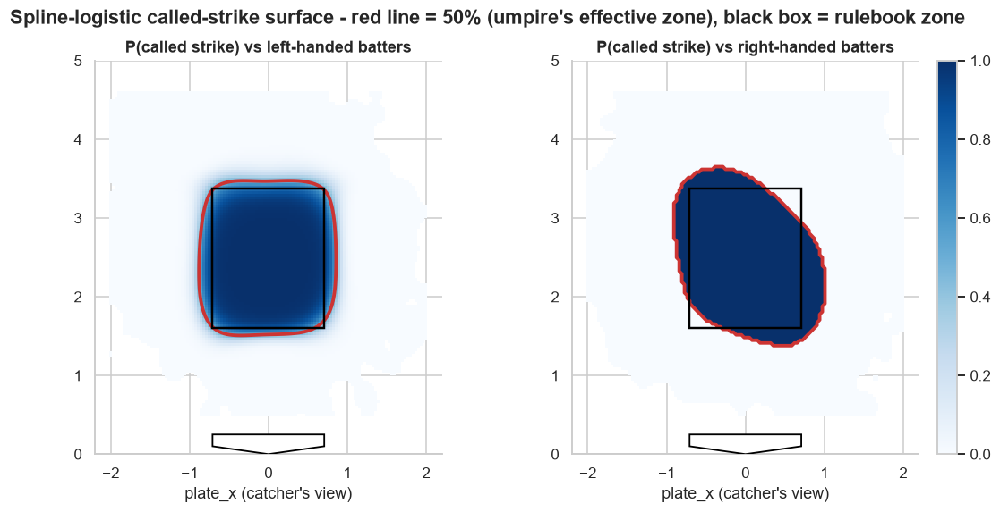

In [29]:
# ---- Called-strike probability surface (what does the umpire actually call?) ----
tk = df[df.is_take & df.result.isin(["Ball", "Called Strike"])].dropna(subset=["plate_x", "plate_z"]).copy()
tk = tk[tk.plate_x.abs().lt(3.4) & tk.plate_z.between(0.1, 5.9)]   # drop wild pitches outside the spline range (all balls)
tk["cs"] = tk.is_called_strike.astype(int)
gx, gz = np.meshgrid(np.linspace(-2, 2, 120), np.linspace(0.5, 4.6, 120))
grid = pd.DataFrame({"plate_x": gx.ravel(), "plate_z": gz.ravel()})
spl = "cs ~ te(bs(plate_x, df=5, lower_bound=-3.5, upper_bound=3.5), bs(plate_z, df=5, lower_bound=0, upper_bound=6))"
surf = {}
for side in ["L", "R"]:
    d = tk[tk.stand == side]
    mod = smf.glm(spl, data=d, family=sm.families.Binomial()).fit()
    p_hat = mod.predict(grid).values.reshape(gx.shape)
    dens, _, _ = np.histogram2d(d.plate_x, d.plate_z, bins=[120, 120], range=[[-2, 2], [0.5, 4.6]])
    support = gaussian_filter(dens, 3).T > 0.05                      # blank cells with almost no pitches (no extrapolation)
    surf[side] = np.where(support, p_hat, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, side, lab in zip(axes, ["L", "R"], ["vs left-handed batters", "vs right-handed batters"]):
    im = ax.pcolormesh(gx, gz, surf[side], cmap="Blues", vmin=0, vmax=1, shading="auto")
    ax.contour(gx, gz, surf[side], levels=[.5], colors=[CUBS_RED], linewidths=2.5)
    draw_zone(ax, inner=False); ax.set_title(f"P(called strike) {lab}"); ax.set_xlabel("plate_x (catcher's view)")
plt.colorbar(im, ax=axes, fraction=.025, pad=.02)
fig.suptitle("Spline-logistic called-strike surface - red line = 50% (umpire's effective zone), black box = rulebook zone", fontweight="bold")
plt.show()

### 5.4 Hypothesis tests with effect sizes

In [30]:
from itertools import combinations

# (1) velocity differences between seasons: Kruskal-Wallis + pairwise Mann-Whitney (Holm-adjusted) + Cohen's d
groups_v = {s: g.release_speed.dropna().values for s, g in df.groupby("season")}
H, p_kw = stats.kruskal(*groups_v.values())
print(f"Kruskal-Wallis across seasons: H = {H:.1f}, p = {p_kw:.2e}")
rows = []
for a, b in combinations(groups_v, 2):
    u, p = stats.mannwhitneyu(groups_v[a], groups_v[b])
    sp_ = np.sqrt((groups_v[a].var(ddof=1) + groups_v[b].var(ddof=1)) / 2)
    rows.append((f"{a} vs {b}", groups_v[b].mean() - groups_v[a].mean(), (groups_v[b].mean() - groups_v[a].mean()) / sp_, p))
pw = pd.DataFrame(rows, columns=["comparison", "diff (mph)", "Cohen d", "p_raw"])
from statsmodels.stats.multitest import multipletests
pw["p_holm"] = multipletests(pw.p_raw, method="holm")[1]
display(pw.assign(p_raw=pw.p_raw.map("{:.1e}".format), p_holm=pw.p_holm.map("{:.1e}".format)).round(4))
print("Caution: the staff changes every year, so season gaps mix pitcher turnover with true velocity change - see the mixed model below.")

# (2) platoon splits: do hitters miss more against the opposite-handed fastball?
swp = df[df.is_swing]
ct = pd.crosstab(swp.platoon_adv, swp.is_whiff)
chi2, p_chi, _, _ = stats.chi2_contingency(ct)
r1, r0 = swp[swp.platoon_adv].is_whiff.mean(), swp[~swp.platoon_adv].is_whiff.mean()
se = np.sqrt(r1 * (1 - r1) / ct.loc[True].sum() + r0 * (1 - r0) / ct.loc[False].sum())
print(f"\nWhiff/swing: opposite-handed {r1:.3f} vs same-handed {r0:.3f}; diff = {r1 - r0:+.3f} "
      f"(95% CI {r1 - r0 - 1.96 * se:+.3f} to {r1 - r0 + 1.96 * se:+.3f}); chi2 = {chi2:.1f}, p = {p_chi:.3g}")

Kruskal-Wallis across seasons: H = 935.9, p = 1.45e-202


,comparison,diff (mph),Cohen d,p_raw,p_holm
0,2023 vs 2024,-0.3835,-0.1350,2.6e-08,5.2e-08
1,2023 vs 2025,0.7729,0.2768,4.7e-42,1.9e-41
2,2023 vs 2026,0.4601,0.1692,3.7e-20,1.1e-19
3,2024 vs 2025,1.1564,0.4525,3.0e-185,1.8e-184
4,2024 vs 2026,0.8436,0.3409,6.7e-81,3.3e-80
5,2025 vs 2026,-0.3128,-0.1293,2.8e-08,5.2e-08


Caution: the staff changes every year, so season gaps mix pitcher turnover with true velocity change - see the mixed model below.

Whiff/swing: opposite-handed 0.183 vs same-handed 0.196; diff = -0.012 (95% CI -0.027 to +0.002); chi2 = 2.7, p = 0.1


In [31]:
# (3) times through the order: do fastballs get worse as hitters see them again?
tto = df.groupby("tto").apply(lambda g: pd.Series({
    "pitches": len(g), "velo": g.release_speed.mean(),
    "whiff/swing %": g[g.is_swing].is_whiff.mean() * 100, "CSW %": g.is_csw.mean() * 100,
    "hard-hit % (BIP)": (g[g.is_bip].launch_speed >= 95).mean() * 100,
    "xwOBAcon": g[g.is_bip].estimated_woba_using_speedangle.mean(), "RV/100": g.rv_pitcher.mean() * 100})).round(2)
display(tto)
print("Note: raw by-TTO velocity gaps mix starters with relievers; the within-pitcher model below removes that composition effect.")
_sw50 = sw.groupby("pitcher").whiff.transform("size") >= 50
m_tto = smf.logit("whiff ~ tto + C(pitcher)", data=sw[_sw50].assign(tto=sw[_sw50].tto.astype(float))).fit(disp=0, cov_type="cluster", cov_kwds={"groups": sw[_sw50].game_pk})
print(f"Within-pitcher whiff odds ratio per extra trip through the order: OR = {np.exp(m_tto.params['tto']):.3f} "
      f"(95% CI {np.exp(m_tto.conf_int().loc['tto', 0]):.3f}-{np.exp(m_tto.conf_int().loc['tto', 1]):.3f}), p = {m_tto.pvalues['tto']:.3f}")

# (4) cluster (game-level) bootstrap: did the staff's CSW% / whiff% change between full seasons?
gm_ = df.groupby(["season", "game_pk"]).agg(csw=("is_csw", "sum"), n=("is_csw", "size"), wh=("is_whiff", "sum"), sw=("is_swing", "sum")).reset_index()
def boot_diff(a, b, num, den, B_=5000):
    ga, gb = gm_[gm_.season == a], gm_[gm_.season == b]
    ia, ib = rng.integers(0, len(ga), (B_, len(ga))), rng.integers(0, len(gb), (B_, len(gb)))
    ra = ga[num].values[ia].sum(1) / ga[den].values[ia].sum(1); rb = gb[num].values[ib].sum(1) / gb[den].values[ib].sum(1)
    d = (rb - ra) * 100
    return d.mean(), np.percentile(d, [2.5, 97.5]), (d > 0).mean()
for lab, num, den in [("CSW %", "csw", "n"), ("Whiff / swing %", "wh", "sw")]:
    mu, ci, pgt = boot_diff(2024, 2025, num, den)
    print(f"{lab}: 2025 minus 2024 = {mu:+.2f} pts, 95% bootstrap CI [{ci[0]:+.2f}, {ci[1]:+.2f}], P(diff>0) = {pgt:.2f}")

,pitches,velo,whiff/swing %,CSW %,hard-hit % (BIP),xwOBAcon,RV/100
tto,,,,,,,
1,16734.0,94.13,19.87,28.35,46.88,0.39,0.15
2,5595.0,92.82,17.16,27.01,50.13,0.41,0.07
3,2671.0,92.30,15.79,24.63,46.28,0.42,-0.58


Note: raw by-TTO velocity gaps mix starters with relievers; the within-pitcher model below removes that composition effect.
Within-pitcher whiff odds ratio per extra trip through the order: OR = 0.896 (95% CI 0.826-0.971), p = 0.008
CSW %: 2025 minus 2024 = -0.93 pts, 95% bootstrap CI [-2.33, +0.46], P(diff>0) = 0.09
Whiff / swing %: 2025 minus 2024 = -2.12 pts, 95% bootstrap CI [-4.07, -0.22], P(diff>0) = 0.01


### 5.5 Mixed-effects model: does fastball velocity fade within an outing?

Pitchers differ enormously in baseline velocity, so a pooled regression would be misleading. A **linear mixed model** with a random intercept (and random slope) per pitcher estimates the *within-pitcher* fade per 10 fastballs thrown in the game, controlling for season. (`ff_idx` counts fastballs only, so it is a lower bound on pitch count.)

In [32]:
mm = df.dropna(subset=["release_speed"]).copy()
mm["ff10"] = (mm.ff_idx - 1) / 10
try:
    m_fade = smf.mixedlm("release_speed ~ ff10 + C(season)", mm, groups=mm["pitcher"], re_formula="~ff10").fit(reml=True, method="lbfgs")
    kind = "random intercept + random slope"
except Exception as e:
    m_fade = smf.mixedlm("release_speed ~ ff10 + C(season)", mm, groups=mm["pitcher"]).fit(reml=True)
    kind = "random intercept only"
b, se = m_fade.params["ff10"], m_fade.bse["ff10"]
print(f"Model: {kind}.  Velocity change per 10 additional fastballs in the outing: {b:+.3f} mph (95% CI {b - 1.96 * se:+.3f} to {b + 1.96 * se:+.3f})")

# visual: velocity relative to each pitcher-season baseline, by number of fastballs thrown so far
mm["velo_dev"] = mm.release_speed - mm.groupby(["pitcher", "season"]).release_speed.transform("mean")
mm["ff_bin"] = pd.cut(mm.ff_idx, [0, 10, 20, 30, 40, 50, 60, 80], labels=["1-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61+"])
fb = mm.groupby("ff_bin").velo_dev.agg(["mean", "sem", "size"]).reset_index()
fig = go.Figure(go.Scatter(x=fb.ff_bin.astype(str), y=fb["mean"], mode="lines+markers", line=dict(color=CUBS_BLUE, width=3),
                           error_y=dict(type="data", array=1.96 * fb["sem"], color="#9ca3af"),
                           hovertemplate="%{x} FF<br>%{y:+.2f} mph<extra></extra>"))
fig.add_hline(y=0, line_dash="dash")
fig.update_layout(title="Velocity vs. pitcher's own baseline as the outing progresses (95% CI)", height=400,
                  xaxis_title="fastballs thrown so far in the game", yaxis_title="mph vs. own season average")
fig.show()

Model: random intercept + random slope.  Velocity change per 10 additional fastballs in the outing: -0.132 mph (95% CI -0.260 to -0.003)


## 6 · Bayesian models (PyMC)

Pitcher samples are small and uneven (one starter has ~3,000 fastballs, a call-up has 30), which is exactly where **partial pooling** shines. Four models:

| Model | Question |
|---|---|
| **6.1** Hierarchical Binomial | What is each pitcher's *true* whiff-per-swing rate, with honest uncertainty? |
| **6.2** Hierarchical logistic regression | Which pitchers beat what their pitch shape/location predicts? |
| **6.3** Beta-Binomial comparison | Did the staff's whiff rate really change from season to season? |
| **6.4** Change-point model | When did a pitcher's velocity shift, and by how much? |

All use weakly-informative priors, report convergence diagnostics ($\hat R$, effective sample size, divergences), and are checked against the data.

In [33]:
import os
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from scipy.special import expit, logit

N_CORES = max(1, min(4, (os.cpu_count() or 2) - 1))     # explicit so sampling is robust on any machine

def diagnostics(idata, var_names):
    # R-hat / ESS / divergences, written to be robust across ArviZ versions
    try:
        s = az.summary(idata, var_names=var_names)
        rh = next((c for c in s.columns if c.lower().replace("_", "") == "rhat"), None)
        es = next((c for c in s.columns if "ess" in c.lower() and "bulk" in c.lower()), None)
        msg = []
        if rh: msg.append(f"max R-hat = {s[rh].max():.3f}")
        if es: msg.append(f"min bulk ESS = {s[es].min():,.0f}")
        div = int(idata.sample_stats["diverging"].sum())
        msg.append(f"divergences = {div}")
        print(" | ".join(msg))
        return s
    except Exception as e:
        print("diagnostics unavailable:", type(e).__name__, e)

def hdi(x, prob=0.94, axis=0):
    lo, hi = (1 - prob) / 2 * 100, (1 + prob) / 2 * 100
    return np.percentile(x, lo, axis=axis), np.percentile(x, hi, axis=axis)

print("PyMC", pm.__version__, "| ArviZ", az.__version__)

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


PyMC 5.28.5 | ArviZ 0.23.4


### 6.1 Hierarchical whiff-per-swing model

$$
y_i \sim \text{Binomial}(n_i,\ \theta_i),\qquad
\text{logit}(\theta_i) = \mu + \sigma\, z_i,\quad z_i\sim N(0,1),\quad
\mu\sim N(\text{logit}(0.19),1),\ \sigma\sim \text{HalfNormal}(0.5)
$$

($y_i$ = whiffs, $n_i$ = swings against pitcher $i$; non-centred parameterisation for clean sampling.) Pitchers with very few swings are pulled strongly toward the staff mean; heavily used pitchers keep their own signal.

In [34]:
bw = (df[df.is_swing].groupby(["pitcher", "pitcher_name"]).agg(swings=("is_whiff", "size"), whiffs=("is_whiff", "sum")).reset_index())
bw = bw[bw.swings >= 30].sort_values("swings", ascending=False).reset_index(drop=True)
bw["raw"] = bw.whiffs / bw.swings
n_p = len(bw)
print(f"{n_p} pitchers with >= 30 swings; total swings {bw.swings.sum():,}")

with pm.Model() as m_whiff_h:
    mu = pm.Normal("mu", logit(0.19), 1.0)
    sigma = pm.HalfNormal("sigma", 0.5)
    z = pm.Normal("z", 0, 1, shape=n_p)
    theta = pm.Deterministic("theta", pm.math.sigmoid(mu + sigma * z))
    pm.Binomial("y", n=bw.swings.values, p=theta, observed=bw.whiffs.values)
    idata_w = pm.sample(1000, tune=1000, chains=4, target_accept=0.95, cores=N_CORES, random_seed=SEED, progressbar=False)

_ = diagnostics(idata_w, ["mu", "sigma"])
post_theta = idata_w.posterior["theta"].values.reshape(-1, n_p)          # (draws, pitchers)
post_mu = expit(idata_w.posterior["mu"].values.ravel())
post_sigma = idata_w.posterior["sigma"].values.ravel()
print(f"Staff-average whiff/swing: {post_mu.mean():.3f}  (94% HDI {hdi(post_mu)[0]:.3f}-{hdi(post_mu)[1]:.3f});  "
      f"between-pitcher SD on logit scale: {post_sigma.mean():.2f}")

39 pitchers with >= 30 swings; total swings 11,845


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma, z]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 952 seconds.


max R-hat = 1.000 | min bulk ESS = 922 | divergences = 0
Staff-average whiff/swing: 0.193  (94% HDI 0.176-0.211);  between-pitcher SD on logit scale: 0.30


In [35]:
lo, hi = hdi(post_theta)
bw["post_mean"], bw["lo"], bw["hi"] = post_theta.mean(0), lo, hi
bw["P(> staff avg)"] = (post_theta > post_mu[:, None]).mean(0)
ranks = (-post_theta).argsort(1).argsort(1) + 1                          # 1 = best whiff rate in each draw
bw["P(top 3)"] = (ranks <= 3).mean(0)
bw["shrink_pts"] = (bw.post_mean - bw.raw) * 100

# posterior predictive coverage check: does the model's 94% interval contain the observed whiffs?
sim = rng.binomial(bw.swings.values[None, :], post_theta[rng.integers(0, len(post_theta), 2000)])
plo, phi = np.percentile(sim, 3, axis=0), np.percentile(sim, 97, axis=0)
print(f"Posterior predictive check: {np.mean((bw.whiffs >= plo) & (bw.whiffs <= phi)):.0%} of pitchers' observed whiff counts fall inside the model's 94% interval (target ~94%).")

d = bw.sort_values("post_mean")
fig = go.Figure()
fig.add_trace(go.Scatter(x=d.post_mean, y=d.pitcher_name, mode="markers", name="Posterior mean (partial pooling)",
                         error_x=dict(type="data", symmetric=False, array=d.hi - d.post_mean, arrayminus=d.post_mean - d.lo, color="rgba(14,51,134,.45)"),
                         marker=dict(color=CUBS_BLUE, size=9), customdata=np.c_[d.swings, d.raw, d["P(> staff avg)"], d["P(top 3)"]],
                         hovertemplate="<b>%{y}</b><br>posterior mean %{x:.3f}<br>raw %{customdata[1]:.3f} on %{customdata[0]} swings<br>"
                                       "P(> staff avg) %{customdata[2]:.2f} | P(top 3) %{customdata[3]:.2f}<extra></extra>"))
fig.add_trace(go.Scatter(x=d.raw, y=d.pitcher_name, mode="markers", name="Raw rate", marker=dict(color=CUBS_RED, symbol="x", size=8)))
fig.add_vline(x=post_mu.mean(), line_dash="dash", line_color="black", annotation_text="staff avg")
fig.update_layout(title="Whiff per swing - raw vs. Bayesian partial pooling (94% HDI)", height=max(520, 20 * n_p + 160),
                  xaxis_title="whiff rate per swing", legend=dict(orientation="h", y=1.04))
fig.show(); save_fig(fig, "bayes_whiff_forest")
display(bw.sort_values("post_mean", ascending=False)[["pitcher_name", "swings", "raw", "post_mean", "lo", "hi", "P(> staff avg)", "P(top 3)"]].head(10).round(3).reset_index(drop=True))

Posterior predictive check: 97% of pitchers' observed whiff counts fall inside the model's 94% interval (target ~94%).


,pitcher_name,swings,raw,post_mean,lo,hi,P(> staff avg),P(top 3)
0,Jayden Murray,33,0.576,0.330,0.225,0.465,0.997,0.871
1,José Cuas,102,0.353,0.291,0.224,0.369,0.998,0.744
2,Tyson Miller,168,0.298,0.268,0.213,0.328,0.995,0.489
3,Jacob Webb,165,0.267,0.245,0.193,0.304,0.972,0.205
4,Michael Fulmer,36,0.306,0.234,0.161,0.331,0.818,0.178
5,Keegan Thompson,118,0.254,0.232,0.179,0.292,0.900,0.099
6,Drew Pomeranz,320,0.241,0.232,0.194,0.273,0.963,0.058
7,Caleb Thielbar,309,0.236,0.228,0.189,0.269,0.944,0.051
8,Daniel Palencia,610,0.230,0.226,0.195,0.256,0.966,0.018
9,Luke Little,170,0.229,0.219,0.171,0.273,0.824,0.040


### 6.2 Hierarchical logistic regression - skill beyond the pitch itself

Now the whiff probability depends on **how hard/where the pitch was thrown** and on a **pitcher random intercept** $u_j$. After conditioning on velocity, spin, movement and location, a persistently positive $u_j$ means a pitcher misses more bats than his raw stuff predicts (deception, tunnelling, sequencing - things not in the covariates).

$$
\text{logit}\,P(\text{whiff}_{ij}) = \alpha + \mathbf x_{ij}^\top\boldsymbol\beta + u_{j},\quad u_j = \tau\, z_j,\ \ \tau\sim\text{HalfNormal}(0.5)
$$

In [ ]:
cov = ["release_speed_z", "release_spin_rate_z", "ivb_in_z", "armside_in_z", "release_extension_z", "plate_z_c", "plate_z_c2", "abs_plate_x", "in_zone_i", "platoon_i"]
sw["plate_z_c2"] = sw.plate_z_c ** 2
keep = sw.groupby("pitcher").whiff.transform("size") >= 30
sb_ = sw[keep].copy()
pid_idx, pid_levels = pd.factorize(sb_.pitcher)
Xb = sb_[cov].values.astype(float)
Xb = (Xb - Xb.mean(0)) / Xb.std(0)                       # standardise so priors are comparable
print(f"{len(sb_):,} swings, {len(pid_levels)} pitchers, {len(cov)} covariates")

with pm.Model() as m_hlr:
    alpha = pm.Normal("alpha", logit(0.19), 1.5)
    beta = pm.Normal("beta", 0, 0.7, shape=len(cov))
    tau = pm.HalfNormal("tau", 0.5)
    zj = pm.Normal("zj", 0, 1, shape=len(pid_levels))
    u = pm.Deterministic("u", tau * zj)
    eta = alpha + pm.math.dot(Xb, beta) + u[pid_idx]
    pm.Bernoulli("y", logit_p=eta, observed=sb_.whiff.values)
    idata_h = pm.sample(1000, tune=1000, chains=4, target_accept=0.95, cores=N_CORES, random_seed=SEED, progressbar=False)

_ = diagnostics(idata_h, ["alpha", "beta", "tau"])
b_post = idata_h.posterior["beta"].values.reshape(-1, len(cov))
u_post = idata_h.posterior["u"].values.reshape(-1, len(pid_levels))
tau_post = idata_h.posterior["tau"].values.ravel()
print(f"Between-pitcher SD of unexplained skill (tau): {tau_post.mean():.3f} logit units  (94% HDI {hdi(tau_post)[0]:.3f}-{hdi(tau_post)[1]:.3f})")

In [ ]:
labels = ["Velocity", "Spin rate", "IVB", "Arm-side run", "Extension", "Height", "Height^2", "Dist. from center", "In zone", "Opposite-handed"]
bl, bh = hdi(b_post)
fb_ = pd.DataFrame({"effect": labels, "mean": b_post.mean(0), "lo": bl, "hi": bh}).sort_values("mean")
fig1 = go.Figure(go.Scatter(x=fb_["mean"], y=fb_.effect, mode="markers", marker=dict(size=10, color=np.where((fb_.lo > 0) | (fb_.hi < 0), CUBS_RED, GREY)),
                            error_x=dict(type="data", symmetric=False, array=fb_.hi - fb_["mean"], arrayminus=fb_["mean"] - fb_.lo, color="#9ca3af")))
fig1.add_vline(x=0, line_dash="dash")
fig1.update_layout(title="Posterior effects on whiff log-odds (per +1 SD, 94% HDI; red = interval excludes 0)", height=430, xaxis_title="log-odds")

ul, uh = hdi(u_post)
pu = (pd.DataFrame({"pitcher": pid_levels}).merge(bw[["pitcher", "pitcher_name", "swings"]], on="pitcher")
        .assign(u=u_post.mean(0), lo=ul, hi=uh, P_pos=(u_post > 0).mean(0)).sort_values("u"))
fig2 = go.Figure(go.Scatter(x=pu.u, y=pu.pitcher_name, mode="markers", marker=dict(size=9, color=np.where(pu.u > 0, CUBS_BLUE, CUBS_RED)),
                            error_x=dict(type="data", symmetric=False, array=pu.hi - pu.u, arrayminus=pu.u - pu.lo, color="#cbd5e1"),
                            customdata=np.c_[pu.swings, pu.P_pos], hovertemplate="<b>%{y}</b><br>effect %{x:+.2f}<br>P(>0) %{customdata[1]:.2f}<br>%{customdata[0]} swings<extra></extra>"))
fig2.add_vline(x=0, line_dash="dash")
fig2.update_layout(title="Unexplained whiff skill by pitcher (random effect, 94% HDI) - after controlling for pitch quality & location",
                   height=max(520, 18 * len(pu) + 150), xaxis_title="log-odds above/below what the pitch predicts")
fig1.show(); fig2.show(); save_fig(fig1, "bayes_hlr_effects"); save_fig(fig2, "bayes_hlr_pitcher_effects")
print("Shrunk toward 0 by design: with this little data per pitcher, most intervals cover 0 - the honest takeaway is how little 'hidden' skill the sample can separate from noise.")

### 6.3 Did the staff's whiff rate change? - Beta-Binomial comparison

With a conjugate $\text{Beta}(1,1)$ prior the posterior for each season's whiff-per-swing rate is $\text{Beta}(1+w,\,1+s-w)$. We sample both and compute $P(\text{rate}_B>\text{rate}_A)$ and the posterior of the difference. (Staff composition changes year to year, so read this as *"what did the staff do"*, not *"what did the same pitchers do"*.)

In [36]:
sea = df[df.is_swing].groupby("season").is_whiff.agg(["sum", "size"]).rename(columns={"sum": "whiffs", "size": "swings"})
draws = {s: rng.beta(1 + r.whiffs, 1 + r.swings - r.whiffs, 40000) for s, r in sea.iterrows()}
fig = go.Figure()
for s, c in zip(draws, [CUBS_BLUE, "#3b5bb5", "#7b93d6", CUBS_RED]):
    fig.add_trace(go.Histogram(x=draws[s], name=f"{s} ({sea.loc[s, 'swings']:,} swings)", opacity=.6, nbinsx=80, histnorm="probability density", marker_color=c))
fig.update_layout(barmode="overlay", title="Posterior of staff whiff-per-swing rate by season", xaxis_title="whiff / swing", height=400)
fig.show()
pairs = [(2024, 2025), (2025, 2026), (2024, 2026)]
rows = []
for a, b in pairs:
    dd = (draws[b] - draws[a]) * 100
    rows.append({"comparison": f"{b} minus {a}", "mean diff (pts)": dd.mean(), "94% HDI low": hdi(dd)[0], "94% HDI high": hdi(dd)[1],
                 "P(later season higher)": (dd > 0).mean()})
display(pd.DataFrame(rows).round(3))

,comparison,mean diff (pts),94% HDI low,94% HDI high,P(later season higher)
0,2025 minus 2024,-2.118,-3.668,-0.584,0.005
1,2026 minus 2025,3.210,1.263,5.174,0.999
2,2026 minus 2024,1.092,-0.926,3.141,0.841


### 6.4 Bayesian change-point model for velocity

For one pitcher's game-by-game average velocity $y_t$: a mean $\mu_1$ before an unknown change point $\tau$ and $\mu_2$ after. The discrete $\tau$ is **marginalised analytically** (log-sum-exp over every possible game), which keeps NUTS happy; the posterior of $\tau$ is recovered afterwards.

In [37]:
gmv = (df.groupby(["pitcher", "pitcher_name", "game_date"]).release_speed.agg(["mean", "size"]).reset_index().query("size >= 8"))
cand = gmv.groupby(["pitcher", "pitcher_name"]).size().sort_values(ascending=False)
cp_pid, cp_name = cand.index[0]
ser = gmv[gmv.pitcher == cp_pid].sort_values("game_date").reset_index(drop=True)
y, nobs = ser["mean"].values, len(ser)
print(f"Change-point subject: {cp_name}  ({nobs} games with >= 8 fastballs, {ser.game_date.min():%b %Y} - {ser.game_date.max():%b %Y})")

with pm.Model() as m_cp:
    mu1 = pm.Normal("mu1", y.mean(), 3); mu2 = pm.Normal("mu2", y.mean(), 3)
    sd = pm.HalfNormal("sd", 2)
    ll1 = pm.logp(pm.Normal.dist(mu1, sd), y); ll2 = pm.logp(pm.Normal.dist(mu2, sd), y)
    c1 = pt.cumsum(ll1); c2 = pt.cumsum(ll2[::-1])[::-1]
    ll_tau = c1[:-1] + c2[1:]                                   # change occurs before game index t = 1..n-1
    pm.Potential("marginal", pt.logsumexp(ll_tau) - np.log(nobs - 1))
    pm.Deterministic("ll_tau", ll_tau)
    idata_cp = pm.sample(1000, tune=1000, chains=4, target_accept=0.9, cores=N_CORES, random_seed=SEED, progressbar=False)

_ = diagnostics(idata_cp, ["mu1", "mu2", "sd"])
llt = idata_cp.posterior["ll_tau"].values.reshape(-1, nobs - 1)
w = np.exp(llt - llt.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)
p_tau = w.mean(0)                                               # P(change occurs before game t), t = 1..n-1
m1, m2 = idata_cp.posterior["mu1"].values.ravel(), idata_cp.posterior["mu2"].values.ravel()
tau_hat = int(p_tau.argmax()) + 1
print(f"Most probable change point: before game #{tau_hat + 1} ({ser.game_date[tau_hat]:%Y-%m-%d}), posterior probability {p_tau.max():.2f}")
print(f"Velocity before: {m1.mean():.2f} mph | after: {m2.mean():.2f} mph | shift {np.mean(m2 - m1):+.2f} mph  (94% HDI {hdi(m2 - m1)[0]:+.2f} to {hdi(m2 - m1)[1]:+.2f}); P(|shift| > 0.5 mph) = {np.mean(np.abs(m2 - m1) > .5):.2f}")

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[.68, .32], vertical_spacing=.06,
                    subplot_titles=(f"{cp_name}: game-average fastball velocity", "Posterior probability of the change point"))
fig.add_trace(go.Scatter(x=ser.game_date, y=y, mode="markers", name="game average", marker=dict(color=CUBS_BLUE, size=7)), 1, 1)
step = np.r_[np.full(tau_hat, m1.mean()), np.full(nobs - tau_hat, m2.mean())]
fig.add_trace(go.Scatter(x=ser.game_date, y=step, mode="lines", name="posterior mean level", line=dict(color=CUBS_RED, width=3, shape="hv")), 1, 1)
fig.add_trace(go.Bar(x=ser.game_date[1:], y=p_tau, marker_color=CUBS_RED, name="P(change here)"), 2, 1)
fig.update_layout(height=620, showlegend=True); fig.update_yaxes(title_text="mph", row=1, col=1); fig.update_yaxes(title_text="probability", row=2, col=1)
fig.show() 
save_fig(fig, "bayes_changepoint")
print("Tip: a change point right after an off-season gap is the model rediscovering 'new season, new velocity'; one mid-season can flag a mechanical change or injury.")

Change-point subject: Daniel Palencia  (81 games with >= 8 fastballs, Jul 2023 - Jun 2026)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu1, mu2, sd]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 452 seconds.


max R-hat = 1.000 | min bulk ESS = 2,270 | divergences = 0
Most probable change point: before game #33 (2025-05-04), posterior probability 0.24
Velocity before: 98.25 mph | after: 99.59 mph | shift +1.34 mph  (94% HDI +0.92 to +1.80); P(|shift| > 0.5 mph) = 1.00


Tip: a change point right after an off-season gap is the model rediscovering 'new season, new velocity'; one mid-season can flag a mechanical change or injury.


## 7 · Machine learning

| Model | Target | Why |
|---|---|---|
| **7.1** LightGBM multiclass | Pitch result (ball / called strike / swinging strike / foul / in play) | Predict what a fastball does; explain it with SHAP; used later for counterfactuals |
| **7.2** LightGBM binary | Whiff given swing | Compare ML with the logistic model; partial-dependence curves |
| **7.3** "Stuff+" score | Whiff-on-swing from pitch shape alone (leave-pitcher-out, with a validity check) | Rate fastballs by *physical quality*, independent of results luck |
| **7.4** KMeans + PCA | Pitcher fastball profile | Discover fastball archetypes on the staff |
| **7.5** Counterfactuals | +/- velocity | "What if this fastball were 2 mph faster?" - feeds the simulator |

**Validation is out-of-time:** train on 2023-2025, test on 2026 (never seen). Early stopping uses the *latest* slice of training data. Pitcher identity is deliberately **not** a feature so the models generalise to new arms.

In [38]:
import lightgbm as lgb
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score, confusion_matrix, r2_score
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ml = df.copy()
ml["throws_R"] = ml.p_throws.eq("R").astype(int)
ml["stand_R"] = ml.stand.eq("R").astype(int)
ml["runners_on_i"] = ml.runners_on.astype(int)
ml["platoon_i"] = ml.platoon_adv.astype(int)
ml["zone_rel_z"] = (ml.plate_z - ml.sz_bot) / (ml.sz_top - ml.sz_bot)           # 0 = knees, 1 = letters
ml["spin_axis_x"] = np.sin(np.radians(ml.spin_axis)); ml["spin_axis_y"] = np.cos(np.radians(ml.spin_axis))

STUFF = ["release_speed", "release_spin_rate", "spin_axis_x", "spin_axis_y", "ivb_in", "armside_in", "release_extension",
         "release_pos_z", "release_x_norm", "arm_angle", "throws_R"]
LOCN = ["plate_x", "plate_z", "inside_x", "zone_rel_z"]
CTX = ["balls", "strikes", "outs_when_up", "runners_on_i", "platoon_i", "stand_R", "tto"]
FEATS = STUFF + LOCN + CTX

CLASSES = ["Ball", "Called Strike", "Swinging Strike", "Foul", "In Play"]
cmap_ = {c: i for i, c in enumerate(CLASSES)}
mlc = ml[ml.result.isin(CLASSES)].dropna(subset=["plate_x", "plate_z", "release_speed", "ivb_in"]).copy()
mlc["y"] = mlc.result.map(cmap_)

train_all = mlc[mlc.season <= 2025].sort_values("game_date")
test = mlc[mlc.season == 2026]
cut = train_all.game_date.quantile(0.88)                                          # last 12% of train (by time) = validation
tr, va = train_all[train_all.game_date <= cut], train_all[train_all.game_date > cut]
print(f"train {len(tr):,} | validation {len(va):,} | out-of-time test (2026) {len(test):,}")

train 18,294 | validation 2,478 | out-of-time test (2026) 4,184


### 7.1 Pitch-outcome classifier

In [39]:
lgb_params = dict(objective="multiclass", n_estimators=2000, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0, random_state=SEED, verbose=-1, n_jobs=-1)
clf = lgb.LGBMClassifier(**lgb_params)
clf.fit(tr[FEATS], tr.y, eval_set=[(va[FEATS], va.y)], eval_metric="multi_logloss",
        callbacks=[lgb.early_stopping(60, verbose=False)])
print("best iteration:", clf.best_iteration_)

P_test = clf.predict_proba(test[FEATS]); y_test = test.y.values

# baselines on the SAME out-of-time test set
prior = np.bincount(tr.y, minlength=5) / len(tr)
P_prior = np.tile(prior, (len(test), 1))
cnt_model = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000))
cnt_model.fit(tr[["balls", "strikes"]].astype(str), tr.y)
P_cnt = cnt_model.predict_proba(test[["balls", "strikes"]].astype(str))

def eval_probs(P, y):
    return {"log loss": log_loss(y, P, labels=range(5)), "accuracy": accuracy_score(y, P.argmax(1)),
            "macro AUC (OvR)": roc_auc_score(y, P, multi_class="ovr", labels=range(5))}
perf = pd.DataFrame({"League prior": eval_probs(P_prior, y_test), "Count-only logistic": eval_probs(P_cnt, y_test),
                     "LightGBM (stuff + location + context)": eval_probs(P_test, y_test)}).T
display(perf.round(4))
skill = 1 - perf.loc["LightGBM (stuff + location + context)", "log loss"] / perf.loc["League prior", "log loss"]
print(f"Log-loss improvement over the league prior: {skill:.1%}")

best iteration: 261


,log loss,accuracy,macro AUC (OvR)
League prior,1.5414,0.3310,0.5000
Count-only logistic,1.4783,0.3482,0.6135
LightGBM (stuff + location + context),0.9924,0.5825,0.8268


Log-loss improvement over the league prior: 35.6%


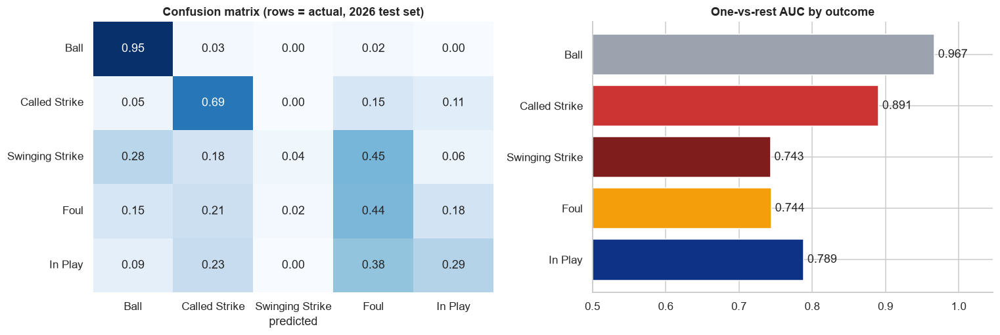

In [40]:
# ---- confusion matrix, per-class AUC, calibration ----
cm = confusion_matrix(y_test, P_test.argmax(1), normalize="true")
auc_c = [roc_auc_score((y_test == k).astype(int), P_test[:, k]) for k in range(5)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(pd.DataFrame(cm, index=CLASSES, columns=CLASSES), annot=True, fmt=".2f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Confusion matrix (rows = actual, 2026 test set)"); axes[0].set_xlabel("predicted")
axes[1].barh(CLASSES[::-1], auc_c[::-1], color=[OUTCOME_COLORS[c] for c in CLASSES[::-1]])
for i, v in enumerate(auc_c[::-1]): axes[1].text(v + .005, i, f"{v:.3f}", va="center")
axes[1].set_xlim(.5, max(auc_c) + .08); axes[1].set_title("One-vs-rest AUC by outcome"); plt.tight_layout(); plt.show()

fig = go.Figure(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color="black", dash="dash"), name="perfect"))
for k, c in enumerate(CLASSES):
    frac, mean_p = calibration_curve((y_test == k).astype(int), P_test[:, k], n_bins=8, strategy="quantile")
    fig.add_trace(go.Scatter(x=mean_p, y=frac, mode="lines+markers", name=c, line=dict(color=OUTCOME_COLORS[c], width=3)))
fig.update_layout(title="Calibration on 2026 pitches: predicted probability vs. observed frequency", height=460, width=720,
                  xaxis_title="predicted probability", yaxis_title="observed frequency")
fig.show(); save_fig(fig, "ml_calibration")

In [41]:
# ---- SHAP: what drives each outcome? ----
Xs = test[FEATS].sample(min(1500, len(test)), random_state=SEED)
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xs)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv                       # -> (n, features, classes)
imp = pd.DataFrame(np.abs(sv).mean(0), index=FEATS, columns=CLASSES)
imp["total"] = imp.sum(1); imp = imp.sort_values("total")
fig = go.Figure([go.Bar(y=imp.index, x=imp[c], name=c, orientation="h", marker_color=OUTCOME_COLORS[c]) for c in CLASSES])
fig.update_layout(barmode="stack", title="Mean |SHAP| by feature and outcome (what moves the prediction)", height=620, xaxis_title="mean |SHAP value|")
fig.show(); save_fig(fig, "ml_shap_importance")

### 7.2 Whiff-on-swing: ML vs. logistic regression, SHAP and partial dependence

  File "C:\Users\Lehma\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Lehma\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Lehma\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Lehma\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


2026 out-of-time AUC for whiff-on-swing: LightGBM = 0.710 | Logistic = 0.689  (base rate 0.203, n = 2,067)


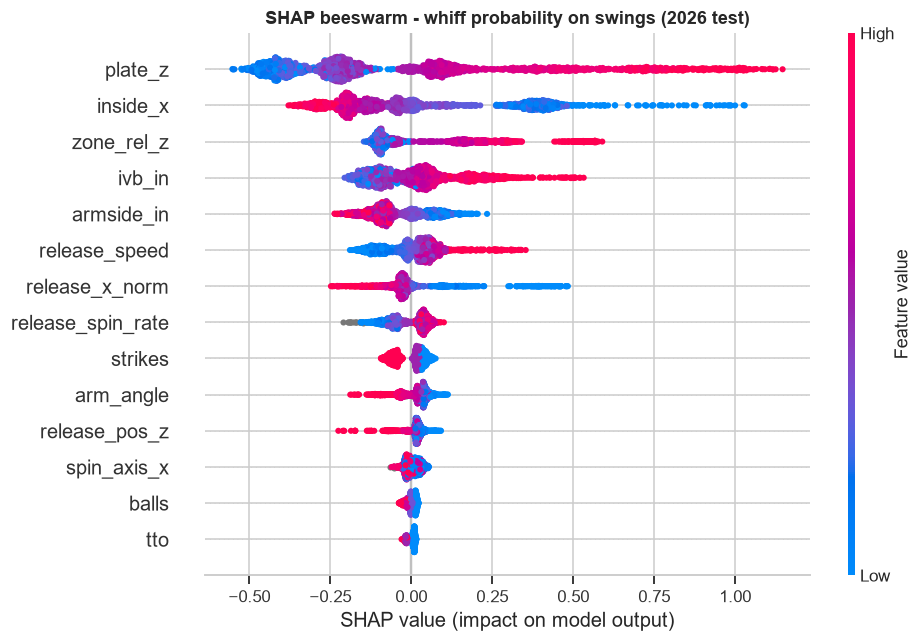

In [42]:
swm = mlc[mlc.is_swing].copy(); swm["w"] = swm.is_whiff.astype(int)
tr_w, te_w = swm[swm.season <= 2025], swm[swm.season == 2026]
cut_w = tr_w.game_date.quantile(0.85)
a_w, v_w = tr_w[tr_w.game_date <= cut_w], tr_w[tr_w.game_date > cut_w]
wfeat = STUFF + LOCN + ["balls", "strikes", "platoon_i", "stand_R", "tto"]

gbm_w = lgb.LGBMClassifier(objective="binary", n_estimators=2000, learning_rate=0.02, num_leaves=7, min_child_samples=60,
                           subsample=.8, subsample_freq=1, colsample_bytree=.7, reg_lambda=5, random_state=SEED, verbose=-1)
gbm_w.fit(a_w[wfeat], a_w.w, eval_set=[(v_w[wfeat], v_w.w)], eval_metric="auc", callbacks=[lgb.early_stopping(80, verbose=False)])
lr_w = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
lr_w.fit(tr_w[wfeat].fillna(tr_w[wfeat].median()), tr_w.w)

auc_gbm = roc_auc_score(te_w.w, gbm_w.predict_proba(te_w[wfeat])[:, 1])
auc_lr = roc_auc_score(te_w.w, lr_w.predict_proba(te_w[wfeat].fillna(tr_w[wfeat].median()))[:, 1])
print(f"2026 out-of-time AUC for whiff-on-swing: LightGBM = {auc_gbm:.3f} | Logistic = {auc_lr:.3f}  (base rate {te_w.w.mean():.3f}, n = {len(te_w):,})")

Xw = te_w[wfeat]
sv_w = shap.TreeExplainer(gbm_w).shap_values(Xw)
sv_w = sv_w[1] if isinstance(sv_w, list) else sv_w
plt.figure(figsize=(9, 6)); shap.summary_plot(sv_w, Xw, show=False, max_display=14, plot_size=None)
plt.title("SHAP beeswarm - whiff probability on swings (2026 test)", fontweight="bold"); plt.tight_layout(); plt.show()

In [43]:
# ---- interactive partial dependence: how does whiff probability move with velocity, height and spin? ----
def pdp(model, X, feat, grid):
    out = []
    for g in grid:
        Xg = X.copy(); Xg[feat] = g
        out.append(model.predict_proba(Xg)[:, 1].mean())
    return np.array(out)

Xbase = swm[wfeat].sample(2500, random_state=SEED)
specs = {"release_speed": ("Velocity (mph)", np.linspace(88, 100, 25)), "plate_z": ("Pitch height (ft)", np.linspace(0.8, 4.8, 25)),
         "release_spin_rate": ("Spin rate (rpm)", np.linspace(2000, 2700, 25)), "ivb_in": ("Induced vertical break (in)", np.linspace(9, 23, 25))}
fig = go.Figure()
for i, (f, (lab, grid)) in enumerate(specs.items()):
    fig.add_trace(go.Scatter(x=grid, y=pdp(gbm_w, Xbase, f, grid) * 100, mode="lines+markers", line=dict(color=CUBS_BLUE, width=3), visible=(i == 0), name=lab))
btn = [dict(label=lab, method="update", args=[{"visible": [j == i for j in range(len(specs))]}, {"xaxis.title.text": lab}]) for i, (f, (lab, g)) in enumerate(specs.items())]
fig.update_layout(title="Partial dependence of whiff-per-swing (%), holding everything else at observed values", height=430,
                  xaxis_title="Velocity (mph)", yaxis_title="whiff / swing (%)", updatemenus=[dict(buttons=btn, x=0, y=1.18, xanchor="left")])
fig.show(); save_fig(fig, "ml_partial_dependence")

### 7.3 A "Stuff+" score from pitch shape alone

A model that sees **only physical properties** (velocity, spin, spin axis, movement, extension, release point) and predicts the probability the pitch is **missed if swung at**. It is trained on swings and then used to score *every* pitch. Two safeguards keep it honest:

- **Leave-pitcher-out validation:** every pitcher is scored by a model that never saw him (5 folds grouped by pitcher). Pitch shape is almost a fingerprint of the pitcher, so game-grouped folds would let the model memorise results and the "stuff" score would just echo past outcomes.
- **A validity check:** we report the out-of-sample AUC and whether pitcher-level Stuff+ actually lines up with pitcher-level whiff rate.

Scale: 100 = average, 10 points = 1 SD of pitch-level scores (higher = more swing-and-miss potential).

> Expect modest signal. With ~70 pitchers and one pitch type, shape alone explains only a little of why a fastball misses bats - location and context matter more (Section 7.2).

In [44]:
sd_ = ml.dropna(subset=STUFF[:-1]).copy()
sd_["w"] = sd_.is_whiff.astype(int)
stuff_score = np.zeros(len(sd_))
for tr_i, te_i in GroupKFold(n_splits=5).split(sd_, groups=sd_.pitcher):
    trn_ = sd_.iloc[tr_i]; trn_ = trn_[trn_.is_swing]
    m_ = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=100, subsample=.8, subsample_freq=1,
                            colsample_bytree=.8, reg_lambda=10, random_state=SEED, verbose=-1)
    m_.fit(trn_[STUFF], trn_.w)
    stuff_score[te_i] = m_.predict_proba(sd_.iloc[te_i][STUFF])[:, 1]            # score all pitches of the held-out pitchers
sd_["pred_whiff"] = stuff_score
sw_mask = sd_.is_swing.values
auc_stuff = roc_auc_score(sd_.w[sw_mask], stuff_score[sw_mask])
print(f"Leave-pitcher-out AUC for whiff-on-swing from pitch shape alone = {auc_stuff:.3f}  (0.5 = no signal)")
lg = logit(np.clip(stuff_score, 1e-4, 1 - 1e-4))
sd_["stuff_plus"] = 100 + 10 * (lg - lg.mean()) / lg.std()

stf = (sd_.groupby(["pitcher", "pitcher_name", "p_throws"]).agg(pitches=("stuff_plus", "size"), stuff_plus=("stuff_plus", "mean"), velo=("release_speed", "mean"),
                                                              actual_rv100=("rv_pitcher", lambda s: s.mean() * 100), csw=("is_csw", "mean")).reset_index())
sw_rate = sd_[sd_.is_swing].groupby("pitcher").w.agg(["mean", "size"]).rename(columns={"mean": "whiff_per_swing", "size": "swings"}).reset_index()
stf = stf.merge(sw_rate, on="pitcher", how="left").query("pitches >= @MIN_PITCHES and swings >= 40")
stf["whiff_per_swing"] *= 100; stf["csw"] *= 100
display(stf.sort_values("stuff_plus", ascending=False).head(10).round(2).reset_index(drop=True))
r_s, p_s = stats.spearmanr(stf.stuff_plus, stf.whiff_per_swing); r_v, p_v = stats.spearmanr(stf.stuff_plus, stf.actual_rv100)
print(f"Across {len(stf)} pitchers (each scored by models that never saw him): Spearman(Stuff+, actual whiff/swing) = {r_s:.2f} (p={p_s:.3f}); "
      f"Spearman(Stuff+, actual RV/100) = {r_v:.2f} (p={p_v:.3f})")
if p_s > 0.05:
    print("-> Validity is WEAK: treat Stuff+ as a rough directional score, not a ranking. (Pitcher-level n is small, and shape alone explains little of whiff rate.)")

fig = px.scatter(stf, x="stuff_plus", y="whiff_per_swing", size="pitches", color="actual_rv100", color_continuous_scale="RdBu", color_continuous_midpoint=0,
                 text=stf.pitcher_name.str.split().str[-1], hover_name="pitcher_name", trendline="ols",
                 labels={"stuff_plus": "Fastball Stuff+ (100 = avg)", "whiff_per_swing": "actual whiff / swing %", "actual_rv100": "RV/100"})
fig.update_traces(textposition="top center", selector=dict(mode="markers+text"))
fig.update_layout(title="Fastball 'stuff' (leave-pitcher-out) vs. actual swing-and-miss", height=560)
fig.show(); save_fig(fig, "ml_stuff_plus")

Leave-pitcher-out AUC for whiff-on-swing from pitch shape alone = 0.545  (0.5 = no signal)


,pitcher,pitcher_name,p_throws,pitches,stuff_plus,velo,actual_rv100,csw,whiff_per_swing,swings
0,657097,Jacob Webb,R,316,119.55,94.09,-1.47,27.85,26.67,165.0
1,668338,Tyson Miller,R,345,110.45,89.44,1.37,31.59,29.76,168.0
2,519141,Drew Pomeranz,L,614,109.81,92.73,1.57,31.76,24.06,320.0
3,593576,Héctor Neris,R,389,108.20,93.00,0.63,24.68,16.10,205.0
4,621016,José Cuas,R,189,107.36,92.02,0.49,29.63,35.29,102.0
5,687863,Porter Hodge,R,705,107.08,95.76,0.27,25.96,21.36,295.0
6,690990,Cade Horton,R,945,106.40,95.72,1.22,31.11,14.90,443.0
7,696136,Jordan Wicks,L,693,106.30,92.72,-0.79,25.97,16.37,391.0
8,571510,Matt Boyd,L,1548,104.00,93.16,0.62,23.64,16.96,867.0
9,684007,Shota Imanaga,L,2999,103.61,91.40,-0.20,25.11,17.56,1583.0


Across 29 pitchers (each scored by models that never saw him): Spearman(Stuff+, actual whiff/swing) = 0.19 (p=0.328); Spearman(Stuff+, actual RV/100) = 0.20 (p=0.307)
-> Validity is WEAK: treat Stuff+ as a rough directional score, not a ranking. (Pitcher-level n is small, and shape alone explains little of whiff rate.)


### 7.4 Fastball archetypes: KMeans on pitcher profiles

One row per pitcher (>= `MIN_PITCHES` fastballs). Horizontal features are **mirrored for left-handers** so "arm-side" means the same thing for everyone. Features are standardised, the number of clusters is picked by silhouette score, and PCA gives a 2-D map.

In [45]:
prof_src = ml.dropna(subset=["release_speed", "ivb_in", "armside_in", "release_spin_rate", "release_extension"]).copy()
prof_src["axis_mirror"] = np.where(prof_src.p_throws.eq("L"), 360 - prof_src.spin_axis, prof_src.spin_axis)
prof_src["axis_sin"], prof_src["axis_cos"] = np.sin(np.radians(prof_src.axis_mirror)), np.cos(np.radians(prof_src.axis_mirror))
pf = (prof_src.groupby(["pitcher", "pitcher_name", "p_throws"]).agg(
        pitches=("release_speed", "size"), Velo=("release_speed", "mean"), IVB=("ivb_in", "mean"), ArmSide=("armside_in", "mean"),
        Spin=("release_spin_rate", "mean"), AxisSin=("axis_sin", "mean"), AxisCos=("axis_cos", "mean"), Ext=("release_extension", "mean"),
        RelHt=("release_pos_z", "mean"), RelSide=("release_x_norm", "mean"), ArmAngle=("arm_angle", "mean")).reset_index().query("pitches >= @MIN_PITCHES"))
pf["ArmAngle"] = pf.ArmAngle.fillna(pf.ArmAngle.median())
cl_feats = ["Velo", "IVB", "ArmSide", "Spin", "AxisSin", "AxisCos", "Ext", "RelHt", "RelSide", "ArmAngle"]
Z = StandardScaler().fit_transform(pf[cl_feats])

sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 7)}
best_k = max((k for k in sil if k >= 3), key=sil.get)
print("silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> using k =", best_k)
pf["cluster"] = KMeans(best_k, n_init=50, random_state=SEED).fit_predict(Z)

# name each cluster from its most distinctive features
zc = pd.DataFrame(Z, columns=cl_feats).groupby(pf.cluster.values).mean()
short = {"Velo": "velo", "IVB": "ride", "ArmSide": "arm-side run", "Spin": "spin", "Ext": "extension", "RelHt": "release height", "RelSide": "release width",
         "ArmAngle": "arm angle", "AxisSin": "axis", "AxisCos": "axis"}
def name_cluster(row):
    top = row.drop(["AxisSin", "AxisCos"]).abs().sort_values(ascending=False).index[:2]
    return " + ".join(f"{'high' if row[t] > 0 else 'low'} {short[t]}" for t in top)
pf["archetype"] = pf.cluster.map({c: f"C{c + 1}: {name_cluster(zc.loc[c])}" for c in zc.index})

pca = PCA(2, random_state=SEED); pcs = pca.fit_transform(Z)
pf["PC1"], pf["PC2"] = pcs[:, 0], pcs[:, 1]
load = pd.DataFrame(pca.components_.T, index=cl_feats, columns=["PC1", "PC2"])
fig = px.scatter(pf, x="PC1", y="PC2", color="archetype", size="pitches", hover_name="pitcher_name", text=pf.pitcher_name.str.split().str[-1],
                 hover_data={"Velo": ":.1f", "IVB": ":.1f", "ArmSide": ":.1f", "Spin": ":.0f", "p_throws": True, "PC1": False, "PC2": False},
                 color_discrete_sequence=px.colors.qualitative.Bold)
fig.update_traces(textposition="top center", textfont_size=9)
for f, r in load.iterrows():
    if f in ("AxisSin", "AxisCos"): continue
    fig.add_annotation(x=r.PC1 * 3, y=r.PC2 * 3, ax=0, ay=0, xref="x", yref="y", axref="x", ayref="y", showarrow=True, arrowhead=2, arrowcolor="#9ca3af", text=f, font=dict(size=9, color="#6b7280"))
fig.update_layout(title=f"Cubs fastball archetypes (PCA map; explained variance {pca.explained_variance_ratio_.sum():.0%}; grey arrows = feature directions)", height=640)
fig.show(); save_fig(fig, "ml_archetypes")

prof = pf.groupby("archetype")[cl_feats[:2] + ["ArmSide", "Spin", "Ext", "RelHt"]].mean()
perf_cl = (pf[["pitcher", "archetype"]].merge(stf[["pitcher", "stuff_plus", "csw", "actual_rv100", "whiff_per_swing"]], on="pitcher").groupby("archetype")
             .agg(pitchers=("pitcher", "size"), stuff_plus=("stuff_plus", "mean"), CSW_pct=("csw", "mean"), whiff_swing_pct=("whiff_per_swing", "mean"), RV100=("actual_rv100", "mean")))
display(prof.join(perf_cl).round(2))

silhouette by k: {2: 0.295, 3: 0.194, 4: 0.17, 5: 0.171, 6: 0.176} -> using k = 3


,Velo,IVB,ArmSide,Spin,Ext,RelHt,pitchers,stuff_plus,CSW_pct,whiff_swing_pct,RV100
archetype,,,,,,,,,,,
C1: low ride + low arm angle,92.59,10.29,8.70,2276.06,6.84,4.96,4,104.99,29.42,26.24,0.64
C2: low arm-side run + high spin,93.85,15.75,1.56,2413.61,6.32,6.09,11,100.33,28.26,18.39,0.72
C3: high arm-side run + low spin,94.29,15.49,7.80,2266.57,6.49,5.84,14,99.14,26.94,18.46,-0.66


### 7.5 Counterfactuals: what if the fastball were faster or slower?

Using the full-history pitch-outcome classifier, we **re-score every pitch with velocity shifted by $\Delta$ mph**, everything else held fixed, and average the predicted outcome probabilities. This gives a per-mph effect on outcomes that the simulator in Section 8 can use.

> **Caveat:** this is a *predictive* what-if. Faster pitchers also differ in other ways, and shifting velocity alone ignores that movement and command may change with effort level. Treat it as a directional sensitivity, not a causal estimate.

In [46]:
# refit on all seasons with the early-stopped number of trees
clf_full = lgb.LGBMClassifier(**{**lgb_params, "n_estimators": int(max(clf.best_iteration_, 50) * 1.1)})
clf_full.fit(mlc[FEATS], mlc.y)

DELTAS = [-3, -2, -1, 0, 1, 2, 3]
def class_probs_at(delta, data):
    X = data[FEATS].copy(); X["release_speed"] = X["release_speed"] + delta
    return clf_full.predict_proba(X)

cf_rows = []
base_probs = class_probs_at(0, mlc)
for dlt in DELTAS:
    pr = class_probs_at(dlt, mlc)
    cf_rows.append(dict(delta=dlt, **{c: (pr[:, k].mean() - base_probs[:, k].mean()) * 100 for k, c in enumerate(CLASSES)}))
cf = pd.DataFrame(cf_rows).set_index("delta")
cf["CSW"] = cf["Called Strike"] + cf["Swinging Strike"]
display(cf.round(3).rename_axis("velocity shift (mph)"))

fig = go.Figure()
for c in ["Swinging Strike", "Called Strike", "Foul", "In Play", "Ball"]:
    fig.add_trace(go.Scatter(x=cf.index, y=cf[c], mode="lines+markers", name=c, line=dict(color=OUTCOME_COLORS[c], width=3)))
fig.add_trace(go.Scatter(x=cf.index, y=cf["CSW"], mode="lines+markers", name="CSW", line=dict(color="black", width=3, dash="dot")))
fig.add_hline(y=0, line_color="#9ca3af")
fig.update_layout(title="Predicted change in pitch-result probability if every fastball were X mph faster/slower (percentage points)",
                  xaxis_title="velocity shift (mph)", yaxis_title="change in probability (pts)", height=460)
fig.show(); save_fig(fig, "ml_velocity_counterfactual")

# per-pitcher sensitivity: change in swinging-strike probability for +1 mph
sens = []
for pid, g in mlc.groupby("pitcher"):
    if len(g) >= MIN_PITCHES:
        d1 = class_probs_at(1, g)[:, 2].mean() - class_probs_at(0, g)[:, 2].mean()
        sens.append((g.pitcher_name.iloc[0], len(g), d1 * 100))
sens = pd.DataFrame(sens, columns=["pitcher", "pitches", "swinging-strike pts per +1 mph"]).sort_values("swinging-strike pts per +1 mph", ascending=False)
print("Pitchers whose swing-and-miss probability the model thinks is most velocity-sensitive:")
display(sens.head(8).round(3).reset_index(drop=True))

,Ball,Called Strike,Swinging Strike,Foul,In Play,CSW
velocity shift (mph),,,,,,
-3,-0.301,1.154,-1.040,-0.106,0.293,0.114
-2,-0.177,0.630,-0.737,-0.039,0.323,-0.107
-1,-0.078,0.255,-0.393,0.002,0.213,-0.137
0,0.000,0.000,0.000,0.000,0.000,0.000
1,0.075,-0.182,0.359,0.019,-0.272,0.177
2,0.145,-0.305,0.643,0.034,-0.516,0.338
3,0.208,-0.406,0.854,0.065,-0.721,0.448


Pitchers whose swing-and-miss probability the model thinks is most velocity-sensitive:


,pitcher,pitches,swinging-strike pts per +1 mph
0,Shota Imanaga,3049,0.800
1,Matt Boyd,1584,0.750
2,Nate Pearson,301,0.632
3,Jameson Taillon,2197,0.625
4,José Cuas,189,0.618
5,Héctor Neris,390,0.606
6,Jacob Webb,316,0.584
7,Daniel Palencia,1183,0.446


## 8 · Monte Carlo simulation

We now chain everything together into a **pitch → plate appearance → inning → game** simulator for the *Cubs fastball*.

```
 pitcher's fastball rates (Bayesian-shrunk)  ──►  count Markov chain  ──►  PA outcome probabilities
          ▲                                          (Section 5.2)             (K, BB, 1B, 2B, 3B, HR, Out)
          │                                                                          │
 velocity scenario (Section 7.5)                                                     ▼
                                                              base-out Markov chain / vectorised Monte Carlo
                                                                   ──►  expected runs, run distributions, RA9
```

**What the simulator is - and isn't.** Every pitch is a fastball, so outputs describe a **"fastball-only world"**: the run environment is *not* a realistic MLB inning (real pitchers mix pitches, and defence/sequencing matter). That is fine for what it is built for - comparing pitchers and scenarios *on equal footing* - and the simulated numbers should be read as relative, not absolute, run prevention. Baserunning uses simple, documented advancement assumptions.

**Uncertainty is propagated end-to-end:** each pitcher's rates are drawn from an empirical-Bayes Dirichlet posterior, pushed through the whole chain, and summarised as intervals.

### 8.1 Inputs: shrunk pitcher fastball rates, in-play outcomes, base-running rules

In [47]:
from scipy.special import gammaln
from scipy.optimize import minimize_scalar

# ---------- (a) pitch-result counts per pitcher, count-mix adjusted ----------
sim_df = df[df.result.isin(POUTS)]
CNT = {pid: pd.crosstab(g["count"], g["result"]).reindex(index=COUNT_LABELS, columns=POUTS, fill_value=0).values
       for pid, g in sim_df.groupby("pitcher")}
O_p = {pid: ct.sum(0) for pid, ct in CNT.items()}                                    # observed result counts (6)
n_p = {pid: ct.sum() for pid, ct in CNT.items()}
e_p = {pid: (ct.sum(1) @ P_lg) / ct.sum() for pid, ct in CNT.items()}                # rates expected from his count mix at league-average behaviour

def dm_loglik(k, counts, bases):
    a = k * bases
    n = counts.sum(1)
    return np.sum(gammaln(k) - gammaln(n + k) + np.sum(gammaln(counts + a) - gammaln(a), axis=1))

pids_all = list(CNT)
C_mat = np.array([O_p[p] for p in pids_all], float); B_mat = np.array([e_p[p] for p in pids_all], float)
res = minimize_scalar(lambda lk: -dm_loglik(np.exp(lk), C_mat, B_mat), bounds=(np.log(5), np.log(1e5)), method="bounded")
K_PITCH = float(np.exp(res.x))
print(f"Empirical-Bayes prior strength for pitch-result rates: k = {K_PITCH:,.0f} pseudo-pitches "
      f"(a pitcher with n = k pitches is weighted 50/50 with the league)")

# ---------- (b) balls in play: Out/1B/2B/3B/HR ----------
IP_LAB = ["Out", "1B", "2B", "3B", "HR"]
ipd = df[df.is_bip].copy()
ipd["ip_class"] = ipd.ev_group.replace({"ROE": "1B"})                               # reached on error behaves like a single on the bases
IPC = {pid: ipd[ipd.pitcher == pid].ip_class.value_counts().reindex(IP_LAB, fill_value=0).values for pid in pids_all}
L_ip = ipd.ip_class.value_counts(normalize=True).reindex(IP_LAB).values
C_ip = np.array([IPC[p] for p in pids_all], float)
res2 = minimize_scalar(lambda lk: -dm_loglik(np.exp(lk), C_ip[C_ip.sum(1) > 0], np.tile(L_ip, ((C_ip.sum(1) > 0).sum(), 1))), bounds=(np.log(5), np.log(1e5)), method="bounded")
K_IP = float(np.exp(res2.x))
print(f"Empirical-Bayes prior strength for in-play outcomes: k = {K_IP:,.0f} balls in play")
print("League in-play mix:", {k: round(float(v), 3) for k, v in zip(IP_LAB, L_ip)})

# ---------- (c) double-play / sacrifice-fly rates and advancement assumptions ----------
outs_ip = ipd[ipd.ip_class == "Out"]
mask_1b = outs_ip.on_1b.notna() & (outs_ip.outs_when_up < 2)
mask_3b = outs_ip.on_3b.notna() & (outs_ip.outs_when_up < 2)
P_GDP = outs_ip[mask_1b].events.isin(["grounded_into_double_play", "double_play"]).mean()
P_SF = outs_ip[mask_3b].events.isin(["sac_fly", "sac_fly_double_play"]).mean()
ADV = {"P_S2": 0.60, "P_S1_3": 0.28, "P_D1": 0.40}          # assumptions (typical MLB-like values), not estimated from this file
P_S2, P_S1_3, P_D1 = ADV["P_S2"], ADV["P_S1_3"], ADV["P_D1"]
print(f"\nEstimated from data: P(GIDP | in-play out, runner on 1B, <2 out) = {P_GDP:.3f} (n={mask_1b.sum()}) | P(sac fly | in-play out, runner on 3B, <2 out) = {P_SF:.3f} (n={mask_3b.sum()})")
print("Assumed advancement:", ADV, "-> single: runner from 2B scores / runner from 1B to 3B; double: runner from 1B scores")

Empirical-Bayes prior strength for pitch-result rates: k = 234 pseudo-pitches (a pitcher with n = k pitches is weighted 50/50 with the league)
Empirical-Bayes prior strength for in-play outcomes: k = 402 balls in play
League in-play mix: {'Out': 0.673, '1B': 0.21, '2B': 0.056, '3B': 0.004, 'HR': 0.057}

Estimated from data: P(GIDP | in-play out, runner on 1B, <2 out) = 0.174 (n=511) | P(sac fly | in-play out, runner on 3B, <2 out) = 0.424 (n=92)
Assumed advancement: {'P_S2': 0.6, 'P_S1_3': 0.28, 'P_D1': 0.4} -> single: runner from 2B scores / runner from 1B to 3B; double: runner from 1B scores


In [48]:
# ---------- pitcher posterior -> PA outcome distribution ----------
PA_LAB = ["K", "BB", "1B", "2B", "3B", "HR", "Out"]          # BB includes HBP

def pa_vector(P_count, ip):
    # PA outcome probabilities from a count-by-count pitch-result matrix and an in-play outcome vector (Out,1B,2B,3B,HR)
    Qm, Rm = chain_matrices(P_count)
    Nm = np.linalg.inv(np.eye(12) - Qm); b = (Nm @ Rm)[0]                             # K, BB, HBP, in play
    return np.array([b[0], b[1] + b[2], b[3] * ip[1], b[3] * ip[2], b[3] * ip[3], b[3] * ip[4], b[3] * ip[0]]), Nm.sum(1)[0]

def count_probs(f):
    # league count probabilities tilted by a pitcher's multiplicative result factors f (6,), renormalised within each count
    P = P_lg * f[None, :]
    return P / P.sum(1, keepdims=True)

def draw_factors(pid, D, rng, rho=None, point=False):
    # posterior draws of the pitcher's result-rate factors f = posterior rate / count-mix-expected rate
    a = O_p[pid] + K_PITCH * e_p[pid]
    r = (a / a.sum())[None, :] if point else rng.dirichlet(a, size=D)
    f = r / e_p[pid][None, :]
    if rho is not None: f = f * rho[None, :]
    return f

def draw_ip(pid, D, rng, point=False):
    a = IPC[pid] + K_IP * L_ip
    return (a / a.sum())[None, :] if point else rng.dirichlet(a, size=D)

pa_lg, pitches_pa_lg = pa_vector(P_lg, L_ip)
print("League-average Cubs-fastball PA outcome mix (fastball-only world):")
print(pd.Series(pa_lg, index=PA_LAB).round(3).to_dict(), f"| pitches per PA {pitches_pa_lg:.2f}")

League-average Cubs-fastball PA outcome mix (fastball-only world):
{'K': 0.221, 'BB': 0.073, '1B': 0.149, '2B': 0.039, '3B': 0.003, 'HR': 0.04, 'Out': 0.476} | pitches per PA 3.88


### 8.2 Two independent run engines: exact Markov solution and vectorised Monte Carlo

The 24 base-out states form an absorbing Markov chain, so expected runs to the end of the inning (the **RE24 matrix**) can be solved *exactly* from the PA outcome probabilities. A separate vectorised **Monte Carlo** simulator (thousands of innings in lock-step) is used for run *distributions*. Because they are coded independently, agreement between them is a strong correctness check.

In [49]:
# ---------- exact base-out Markov chain ----------
def sidx(outs, base): return outs * 8 + base
def mkb(a, b, c): return int(a) + 2 * int(b) + 4 * int(c)

def branches(outs, base, o):
    # list of (probability, new_outs, new_base, runs) for PA outcome o from a base-out state
    b1, b2, b3 = bool(base & 1), bool(base & 2), bool(base & 4)
    res_ = []
    add = lambda p, no, nb, r: res_.append((p, no, nb, r)) if p > 0 else None
    if o == "K":
        add(1, outs + 1, base, 0)
    elif o == "BB":
        add(1, outs, mkb(True, b2 or b1, b3 or (b1 and b2)), int(b1 and b2 and b3))
    elif o == "Out":
        rem = 1.0
        if b1 and outs < 2:
            add(P_GDP, outs + 2, mkb(False, False, b2), int(b3 and outs == 0)); rem = 1 - P_GDP
        if b3 and outs < 2:
            add(rem * P_SF, outs + 1, mkb(b1, b2, False), 1); add(rem * (1 - P_SF), outs + 1, base, 0)
        else:
            add(rem, outs + 1, base, 0)
    elif o == "1B":
        for p2, sc2 in ([(P_S2, True), (1 - P_S2, False)] if b2 else [(1.0, None)]):
            if b1: opts1 = [(1.0, "2")] if (b2 and not sc2) else [(P_S1_3, "3"), (1 - P_S1_3, "2")]
            else:  opts1 = [(1.0, None)]
            for p1, dst in opts1:
                add(p2 * p1, outs, mkb(True, dst == "2", (b2 and sc2 is False) or dst == "3"), int(b3) + int(bool(b2 and sc2)))
    elif o == "2B":
        r0 = int(b3) + int(b2)
        if b1: add(P_D1, outs, mkb(False, True, False), r0 + 1); add(1 - P_D1, outs, mkb(False, True, True), r0)
        else:  add(1, outs, mkb(False, True, False), r0)
    elif o == "3B":
        add(1, outs, mkb(False, False, True), int(b1) + int(b2) + int(b3))
    elif o == "HR":
        add(1, outs, 0, int(b1) + int(b2) + int(b3) + 1)
    return res_

M_o = np.zeros((7, 24, 24)); r_o = np.zeros((7, 24))
for oi, o in enumerate(PA_LAB):
    for outs in range(3):
        for base in range(8):
            for p, no, nb, rr in branches(outs, base, o):
                r_o[oi, sidx(outs, base)] += p * rr
                if no < 3: M_o[oi, sidx(outs, base), sidx(no, nb)] += p
assert np.allclose(M_o.sum(0).sum(1) / 7, M_o.sum(0).sum(1) / 7)   # sanity: shapes ok

def exact_re(pa):
    # expected runs to end of inning from each of the 24 base-out states, given PA outcome probabilities
    T = np.tensordot(pa, M_o, axes=(0, 0)); r = pa @ r_o
    return np.linalg.solve(np.eye(24) - T, r)

RE_lg = exact_re(pa_lg)
print(f"Exact expected runs per inning (league-avg Cubs fastball world): {RE_lg[0]:.3f}  ->  RA9 = {9 * RE_lg[0]:.2f}")

Exact expected runs per inning (league-avg Cubs fastball world): 0.453  ->  RA9 = 4.08


Max |MC - exact| over 24 base-out states: 0.019 runs   (MC standard error ~0.01-0.02)   [0.8s]


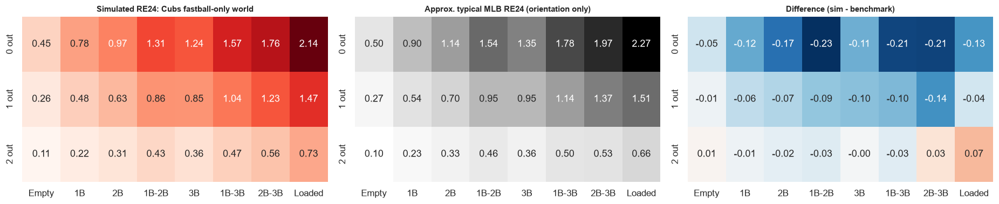

Simulated expected runs for a fresh inning: 0.45 vs ~0.50 benchmark (-9%). The gap reflects the fastball-only diet plus simplified baserunning (no steals, no advancing on outs, no wild pitches), so use the levels loosely and the comparisons seriously.


In [50]:
# ---------- vectorised Monte Carlo (independent implementation) ----------
def simulate_innings(pa_probs, n, rng, start_outs=0, start_base=0):
    pa_probs = np.asarray(pa_probs, float)
    cum = np.cumsum(pa_probs if pa_probs.ndim == 2 else np.tile(pa_probs, (n, 1)), axis=1)
    outs = np.full(n, start_outs); b1 = np.full(n, bool(start_base & 1)); b2 = np.full(n, bool(start_base & 2)); b3 = np.full(n, bool(start_base & 4))
    runs = np.zeros(n, int); active = outs < 3
    while active.any():
        idx = np.where(active)[0]; m = len(idx)
        o = np.minimum((rng.random(m)[:, None] > cum[idx]).sum(1), 6)
        u = rng.random((m, 3))
        B1, B2, B3, O = b1[idx], b2[idx], b3[idx], outs[idx]
        nb1, nb2, nb3, nO, Rn = B1.copy(), B2.copy(), B3.copy(), O.copy(), np.zeros(m, int)
        k = o == 0; nO[k] += 1                                                         # strikeout
        w = o == 1                                                                      # walk / HBP (forced advances)
        Rn[w] += (B1 & B2 & B3)[w]; nb3[w] = (B3 | (B1 & B2))[w]; nb2[w] = (B2 | B1)[w]; nb1[w] = True
        ot = o == 6                                                                     # ball in play, out
        gdp = ot & B1 & (O < 2) & (u[:, 0] < P_GDP)
        nO[gdp] += 2; nb1[gdp] = False; nb2[gdp] = False; nb3[gdp] = B2[gdp]; Rn[gdp] += (B3 & (O == 0))[gdp]
        sf = ot & ~gdp & B3 & (O < 2) & (u[:, 1] < P_SF)
        nO[sf] += 1; nb3[sf] = False; Rn[sf] += 1
        nO[ot & ~gdp & ~sf] += 1
        s1 = o == 2                                                                     # single
        sc2 = B2 & (u[:, 0] < P_S2); st2 = B2 & ~sc2
        to3 = B1 & ~st2 & (u[:, 1] < P_S1_3); to2 = B1 & ~to3
        Rn[s1] += (B3.astype(int) + sc2.astype(int))[s1]; nb3[s1] = (st2 | to3)[s1]; nb2[s1] = to2[s1]; nb1[s1] = True
        d = o == 3; sc1 = B1 & (u[:, 2] < P_D1)                                         # double
        Rn[d] += (B3.astype(int) + B2.astype(int) + sc1.astype(int))[d]; nb3[d] = (B1 & ~sc1)[d]; nb2[d] = True; nb1[d] = False
        t = o == 4                                                                      # triple
        Rn[t] += (B1.astype(int) + B2.astype(int) + B3.astype(int))[t]; nb1[t] = False; nb2[t] = False; nb3[t] = True
        h = o == 5                                                                      # home run
        Rn[h] += (B1.astype(int) + B2.astype(int) + B3.astype(int))[h] + 1; nb1[h] = False; nb2[h] = False; nb3[h] = False
        b1[idx], b2[idx], b3[idx], outs[idx] = nb1, nb2, nb3, nO
        runs[idx] += Rn; active[idx] = nO < 3
    return runs

# ---------- cross-check: MC vs exact for all 24 states ----------
t0 = time.time()
mc_re = np.array([simulate_innings(pa_lg, 20000, rng, o_, b_).mean() for o_ in range(3) for b_ in range(8)])
print(f"Max |MC - exact| over 24 base-out states: {np.abs(mc_re - RE_lg).max():.3f} runs   (MC standard error ~0.01-0.02)   [{time.time() - t0:.1f}s]")

# ---------- RE24 heatmaps: exact vs a rough real-MLB benchmark ----------
BENCH = np.array([[.50, .90, 1.14, 1.54, 1.35, 1.78, 1.97, 2.27],        # 0 out   (approximate typical MLB values, for orientation only)
                  [.27, .54, .70, .95, .95, 1.14, 1.37, 1.51],            # 1 out
                  [.10, .23, .33, .46, .36, .50, .53, .66]])              # 2 out
RE_mat = RE_lg.reshape(3, 8)
cols_ = [BASE_LABELS[i] for i in range(8)]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, M, ttl, cm_ in [(axes[0], RE_mat, "Simulated RE24: Cubs fastball-only world", "Reds"),
                        (axes[1], BENCH, "Approx. typical MLB RE24 (orientation only)", "Greys"),
                        (axes[2], RE_mat - BENCH, "Difference (sim - benchmark)", "RdBu_r")]:
    sns.heatmap(pd.DataFrame(M, index=["0 out", "1 out", "2 out"], columns=cols_), annot=True, fmt=".2f", cmap=cm_,
                center=0 if "Diff" in ttl else None, ax=ax, cbar=False)
    ax.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.show()
print(f"Simulated expected runs for a fresh inning: {RE_mat[0, 0]:.2f} vs ~{BENCH[0, 0]:.2f} benchmark ({(RE_mat[0, 0] / BENCH[0, 0] - 1):+.0%}). "
      "The gap reflects the fastball-only diet plus simplified baserunning (no steals, no advancing on outs, no wild pitches), so use the levels loosely and the comparisons seriously.")

### 8.3 Backtest: do shrunk pitcher rates predict *future* performance better than raw rates?

In [51]:
# Rolling-origin backtest on whiff-per-swing: for each test season Y, estimate every pitcher from seasons < Y only and predict his season-Y rate.
sw_all = df[df.is_swing]
frames = []
for Y in [2024, 2025, 2026]:
    trn, tst = sw_all[sw_all.season < Y], sw_all[sw_all.season == Y]
    a = trn.groupby("pitcher").is_whiff.agg(["sum", "size"]); b_ = tst.groupby("pitcher").is_whiff.agg(["sum", "size"])
    mu0 = a["sum"].sum() / a["size"].sum(); rr = a["sum"] / a["size"]
    vb = max(np.average((rr - mu0) ** 2, weights=a["size"]) - np.average(mu0 * (1 - mu0) / a["size"], weights=a["size"]), 1e-6)
    kappa = max(mu0 * (1 - mu0) / vb - 1, 1)                                  # Beta prior strength by method of moments
    t_ = a.join(b_, lsuffix="_tr", rsuffix="_te", how="inner").query("size_tr >= 20 and size_te >= 20").copy()
    t_["raw"] = t_.sum_tr / t_.size_tr; t_["shrunk"] = (t_.sum_tr + kappa * mu0) / (t_.size_tr + kappa)
    t_["league"] = mu0; t_["actual"] = t_.sum_te / t_.size_te; t_["test_year"] = Y; t_["kappa"] = kappa
    frames.append(t_)
bt = pd.concat(frames)
wrmse = lambda c: np.average((bt[c] - bt.actual) ** 2, weights=bt.size_te) ** .5
tbl = pd.Series({"Raw prior-season rate": wrmse("raw"), "Empirical-Bayes shrunk": wrmse("shrunk"), "League mean only": wrmse("league")}, name="weighted RMSE of predicted whiff rate")
display(tbl.round(4).to_frame())
gain = 1 - wrmse("shrunk") / wrmse("raw")
print(f"{len(bt)} pitcher-seasons across 3 test years (kappa ~ {bt.kappa.mean():.0f} swings). Shrinkage changes RMSE vs raw by {-gain:+.1%} "
      f"({'better' if gain > 0 else 'no better'}); both beat the league mean by {1 - wrmse('shrunk') / wrmse('league'):.1%}." if wrmse("shrunk") < wrmse("league") else
      f"{len(bt)} pitcher-seasons. Shrunk RMSE {wrmse('shrunk'):.4f} vs raw {wrmse('raw'):.4f} vs league {wrmse('league'):.4f}: at this sample size, true pitcher differences in whiff rate are hard to separate from noise.")

,weighted RMSE of predicted whiff rate
Raw prior-season rate,0.0528
Empirical-Bayes shrunk,0.0433
League mean only,0.0421


31 pitcher-seasons. Shrunk RMSE 0.0433 vs raw 0.0528 vs league 0.0421: at this sample size, true pitcher differences in whiff rate are hard to separate from noise.


### 8.4 Simulating every pitcher, with uncertainty

In [52]:
D = 400                                                                    # posterior draws per pitcher
elig = pitcher_tbl.pitcher.tolist()                                        # pitchers with >= MIN_PITCHES fastballs
def pitcher_sim(pid, D, rng, rho=None):
    # posterior draws -> PA vectors -> exact expected runs per inning, plus K%, BB%, wOBA-like index
    F = draw_factors(pid, D, rng, rho); IPd = draw_ip(pid, D, rng)
    pas = np.empty((D, 7)); pit = np.empty(D)
    for i in range(D):
        pas[i], pit[i] = pa_vector(count_probs(F[i]), IPd[i])
    ra9 = np.array([9 * exact_re(p)[0] for p in pas])
    return pas, pit, ra9

t0 = time.time()
sim_res = {pid: pitcher_sim(pid, D, rng) for pid in elig}
print(f"Simulated {len(elig)} pitchers x {D} posterior draws in {time.time() - t0:.1f}s")

rows = []
for pid in elig:
    pas, pit, ra9 = sim_res[pid]
    rows.append(dict(pitcher=pid, pitcher_name=PITCHER_NAMES[pid], pitches=n_p[pid], RA9=ra9.mean(), RA9_lo=np.percentile(ra9, 5), RA9_hi=np.percentile(ra9, 95),
                     K_pct=pas[:, 0].mean() * 100, BB_pct=pas[:, 1].mean() * 100, HR_pct=pas[:, 5].mean() * 100, pitches_per_PA=pit.mean()))
sim_tbl = pd.DataFrame(rows).sort_values("RA9").reset_index(drop=True)
sim_tbl["rank"] = np.arange(1, len(sim_tbl) + 1)
# probability each pitcher is the best / in the top 5 given uncertainty
RA = np.array([sim_res[p][2] for p in sim_tbl.pitcher])                    # (pitchers, draws)
rk = RA.argsort(0).argsort(0) + 1
sim_tbl["P(best)"] = (rk == 1).mean(1); sim_tbl["P(top 5)"] = (rk <= 5).mean(1)
display(sim_tbl.drop(columns=["pitcher", "rank"]).round(2).head(12))

d = sim_tbl.sort_values("RA9", ascending=False)
fig = go.Figure(go.Scatter(x=d.RA9, y=d.pitcher_name, mode="markers", marker=dict(size=10, color=CUBS_BLUE),
                           error_x=dict(type="data", symmetric=False, array=d.RA9_hi - d.RA9, arrayminus=d.RA9 - d.RA9_lo, color="rgba(14,51,134,.35)"),
                           customdata=np.c_[d.K_pct, d.BB_pct, d.HR_pct, d["P(best)"], d.pitches],
                           hovertemplate="<b>%{y}</b><br>RA9 %{x:.2f}<br>K %{customdata[0]:.1f}% | BB %{customdata[1]:.1f}% | HR %{customdata[2]:.1f}%<br>"
                                         "P(best) %{customdata[3]:.2f} | %{customdata[4]} pitches<extra></extra>"))
fig.add_vline(x=9 * RE_lg[0], line_dash="dash", line_color="black", annotation_text="league avg", annotation_position="top")
fig.update_layout(title="Simulated 'fastball-only' runs allowed per 9 (90% interval) - lower is better", height=max(480, 24 * len(d) + 140), xaxis_title="RA9 in the fastball-only world")
fig.show(); save_fig(fig, "sim_pitcher_ra9")

# sanity: does the simulator agree with Statcast's own run values?
mrg = sim_tbl.merge(pitcher_tbl[["pitcher", "RV/100"]], on="pitcher")
rho_s, p_rho = stats.spearmanr(-mrg.RA9, mrg["RV/100"])
print(f"Validation - Spearman(simulated run prevention, Statcast RV/100) = {rho_s:.2f} (p = {p_rho:.4f}, n = {len(mrg)})")

Simulated 29 pitchers x 400 posterior draws in 3.3s


,pitcher_name,pitches,RA9,RA9_lo,RA9_hi,K_pct,BB_pct,HR_pct,pitches_per_PA,P(best),P(top 5)
0,Drew Pomeranz,614,3.17,2.48,4.02,27.71,6.27,3.37,3.90,0.30,0.72
1,Caleb Thielbar,531,3.49,2.69,4.47,25.41,4.87,4.01,3.79,0.10,0.48
2,José Cuas,189,3.52,2.54,4.62,28.36,8.40,3.49,4.01,0.14,0.47
3,Tyson Miller,345,3.54,2.63,4.66,28.31,8.96,3.31,4.03,0.12,0.46
4,Justin Steele,2106,3.63,2.96,4.40,24.66,4.90,3.37,3.80,0.03,0.32
5,Cade Horton,945,3.82,3.07,4.68,19.14,5.85,3.47,3.65,0.02,0.21
6,Brad Keller,470,3.83,2.85,4.85,23.79,8.89,3.56,4.01,0.04,0.26
7,Matt Boyd,1587,3.86,3.16,4.68,20.48,5.61,3.59,3.80,0.01,0.18
8,Jacob Webb,316,3.87,2.89,5.13,26.72,8.03,3.90,4.02,0.04,0.26
9,Daniel Palencia,1188,3.93,3.15,4.79,24.04,9.99,3.31,4.00,0.00,0.15


Validation - Spearman(simulated run prevention, Statcast RV/100) = 0.61 (p = 0.0005, n = 29)


### 8.5 Run distributions: innings and games

In [56]:
n_sim = 300_000
inn = simulate_innings(pa_lg, n_sim, rng)
pmf = np.bincount(np.minimum(inn, 8), minlength=9) / n_sim
print(f"League-average inning: mean {inn.mean():.3f} runs, P(scoreless) = {pmf[0]:.1%}, P(3+ runs) = {(inn >= 3).mean():.1%}, P(5+ runs) = {(inn >= 5).mean():.1%}")

# 9-inning games (innings independent), compared with a Poisson of the same mean
games = rng.choice(inn, size=(100_000, 9)).sum(1)
mu_g, var_g = games.mean(), games.var()
ks = np.arange(0, 26)
pois = stats.poisson.pmf(ks, mu_g)
r_nb = mu_g ** 2 / max(var_g - mu_g, 1e-9); nb = stats.nbinom.pmf(ks, r_nb, r_nb / (r_nb + mu_g))
obs = np.bincount(np.minimum(games, 25), minlength=26) / len(games)
fig = make_subplots(rows=1, cols=2, subplot_titles=("Runs in one inning", f"Runs in a 9-inning game (mean {mu_g:.1f}, var {var_g:.1f})"))
fig.add_trace(go.Bar(x=list(range(9)), y=pmf, marker_color=CUBS_BLUE, name="simulated"), 1, 1)
fig.add_trace(go.Bar(x=ks, y=obs, marker_color=CUBS_BLUE, opacity=.8, name="simulated game"), 1, 2)
fig.add_trace(go.Scatter(x=ks, y=pois, mode="lines", line=dict(color="#9ca3af", dash="dash"), name="Poisson (same mean)"), 1, 2)
fig.add_trace(go.Scatter(x=ks, y=nb, mode="lines", line=dict(color=CUBS_RED, width=3), name="Negative binomial"), 1, 2)
fig.update_xaxes(title_text="runs", row=1, col=1); fig.update_xaxes(title_text="runs", row=1, col=2)
fig.update_layout(height=420, title="Simulated run distributions (league-average Cubs fastball world)", bargap=.05)
fig.show(); save_fig(fig, "sim_run_distributions")
print(f"Variance / mean of runs per game = {var_g / mu_g:.2f} -> runs are over-dispersed relative to Poisson (big innings cluster).")

# best vs worst pitcher: simulated 9-inning games
best, worst = sim_tbl.iloc[0], sim_tbl.iloc[-1]
fig = go.Figure()
summ = []
for pr_, col in [(best, CUBS_BLUE), (worst, CUBS_RED)]:
    pa_pt = pa_vector(count_probs(draw_factors(pr_.pitcher, 1, rng, point=True)[0]), draw_ip(pr_.pitcher, 1, rng, point=True)[0])[0]
    inn_p = simulate_innings(pa_pt, 200_000, rng); g_ = rng.choice(inn_p, size=(60_000, 9)).sum(1)
    fig.add_trace(go.Histogram(x=g_, name=f"{pr_.pitcher_name}", opacity=.6, histnorm="probability", xbins=dict(start=-.5, end=30.5, size=1), marker_color=col))
    summ.append((pr_.pitcher_name, g_.mean(), (g_ == 0).mean() * 100, (g_ >= 5).mean() * 100, (g_ >= 8).mean() * 100))
fig.update_layout(barmode="overlay", title="9-inning outcomes if the same pitcher threw all nine innings (fastball-only world)", xaxis_title="runs allowed", height=420)
save_fig(fig, "pitcher_simulation")
fig.show()
display(pd.DataFrame(summ, columns=["pitcher", "mean runs", "shutout %", "5+ runs %", "8+ runs %"]).round(2))

League-average inning: mean 0.455 runs, P(scoreless) = 74.6%, P(3+ runs) = 5.0%, P(5+ runs) = 0.8%


Variance / mean of runs per game = 2.02 -> runs are over-dispersed relative to Poisson (big innings cluster).


,pitcher,mean runs,shutout %,5+ runs %,8+ runs %
0,Drew Pomeranz,3.12,12.50,24.92,5.72
1,Kyle Hendricks,5.17,4.94,51.57,22.49


### 8.6 Scenario analysis: what is a mile per hour worth?

For each pitcher we re-score his pitches with velocity shifted by $\Delta$ mph (Section 7.5) to get **outcome-rate multipliers** $\rho_\Delta$ (e.g. swinging strikes up 3%), multiply them into his posterior result-rates, and push the result through the same chain. In-play quality is held fixed, so this captures the **strike-zone/whiff channel only** and likely *understates* the benefit of velocity (which also reduces hard contact).

In [54]:
SC_DELTAS = [-2, -1, 0, 1, 2]
def rho_for(pid, delta):
    g = mlc[mlc.pitcher == pid]
    p0, p1 = class_probs_at(0, g).mean(0), class_probs_at(delta, g).mean(0)
    return np.r_[p1 / p0, 1.0]                                                    # 5 classes + HBP (unchanged)

t0 = time.time()
scen = {}                                                                        # scen[delta][pid] = (RA9 draws, K% draws)
for dlt in SC_DELTAS:
    scen[dlt] = {}
    for pid in elig:
        rho = rho_for(pid, dlt) if dlt != 0 else None
        pas, pit, ra9 = pitcher_sim(pid, 200, np.random.default_rng(SEED + 1), rho)       # common random numbers across scenarios
        scen[dlt][pid] = (ra9, pas[:, 0] * 100)
print(f"Scenario engine finished in {time.time() - t0:.1f}s")

w = np.array([n_p[p] for p in elig], float); w /= w.sum()
agg = {dlt: np.array([scen[dlt][p][0] for p in elig]).T @ w for dlt in SC_DELTAS}      # draws of staff RA9
aggk = {dlt: np.array([scen[dlt][p][1] for p in elig]).T @ w for dlt in SC_DELTAS}
diff = {dlt: agg[dlt] - agg[0] for dlt in SC_DELTAS}
sc_tbl = pd.DataFrame({"velocity shift (mph)": SC_DELTAS,
                       "staff RA9": [agg[d_].mean() for d_ in SC_DELTAS],
                       "change in RA9": [diff[d_].mean() for d_ in SC_DELTAS],
                       "90% lo": [np.percentile(diff[d_], 5) for d_ in SC_DELTAS], "90% hi": [np.percentile(diff[d_], 95) for d_ in SC_DELTAS],
                       "K% change (pts)": [(aggk[d_] - aggk[0]).mean() for d_ in SC_DELTAS]}).set_index("velocity shift (mph)")
display(sc_tbl.round(3))

fig = make_subplots(rows=1, cols=2, subplot_titles=("Staff run prevention vs. velocity change", "Per-pitcher effect of +1 mph on RA9"), column_widths=[.45, .55])
fig.add_trace(go.Scatter(x=SC_DELTAS, y=sc_tbl["90% hi"], mode="lines", line=dict(width=0), showlegend=False), 1, 1)
fig.add_trace(go.Scatter(x=SC_DELTAS, y=sc_tbl["90% lo"], mode="lines", line=dict(width=0), fill="tonexty", fillcolor="rgba(14,51,134,.2)", name="90% interval"), 1, 1)
fig.add_trace(go.Scatter(x=SC_DELTAS, y=sc_tbl["change in RA9"], mode="lines+markers", line=dict(color=CUBS_BLUE, width=4), name="staff mean"), 1, 1)
pp = pd.DataFrame({"pitcher": [PITCHER_NAMES[p] for p in elig], "d": [(scen[1][p][0] - scen[0][p][0]).mean() for p in elig]}).sort_values("d")
fig.add_trace(go.Bar(y=pp.pitcher, x=pp.d, orientation="h", marker_color=np.where(pp.d < 0, CUBS_BLUE, CUBS_RED), showlegend=False), 1, 2)
fig.update_xaxes(title_text="velocity shift (mph)", row=1, col=1); fig.update_yaxes(title_text="change in RA9", row=1, col=1)
fig.update_xaxes(title_text="change in RA9 for +1 mph", row=1, col=2)
fig.update_layout(height=max(520, 17 * len(pp) + 160), title="Value of velocity in the fastball-only world (whiff / strike-zone channel only)")
fig.show(); save_fig(fig, "sim_velocity_scenarios")
per_mph = sc_tbl.loc[1, "change in RA9"] - sc_tbl.loc[-1, "change in RA9"]
print(f"Net effect: roughly {per_mph / 2:+.3f} RA9 per +1 mph (central difference), via strikes and misses alone.")

Scenario engine finished in 16.6s


,staff RA9,change in RA9,90% lo,90% hi,K% change (pts)
velocity shift (mph),,,,,
-2,4.257,0.088,0.075,0.104,-0.936
-1,4.226,0.057,0.050,0.066,-0.598
0,4.169,0.000,0.000,0.000,0.000
1,4.107,-0.062,-0.072,-0.055,0.688
2,4.055,-0.113,-0.130,-0.100,1.270


Net effect: roughly -0.060 RA9 per +1 mph (central difference), via strikes and misses alone.


## 9 · Findings, limitations and exports

In [54]:
# ---- auto-generated headline findings (every number comes from the models above) ----
lines = []
lines.append(f"DATA   {len(df):,} Cubs fastballs, {df.game_pk.nunique()} games, {df.pitcher.nunique()} pitchers, {df.season.min()}-{df.season.max()}. "
             f"Average velocity {df.release_speed.mean():.1f} mph; whiff/swing {df[df.is_swing].is_whiff.mean():.1%}; CSW {df.is_csw.mean():.1%}.")
lines.append(f"MARKOV A fastball-only PA ends in a strikeout {B[0, 0]:.1%} / walk {B[0, 1] + B[0, 2]:.1%} / ball in play {B[0, 3]:.1%}, averaging {pitches_left[0]:.2f} pitches; "
             f"{absorb_tbl.K.idxmax()} is the count with the highest strikeout chance ({absorb_tbl.K.max():.0%}); {absorb_tbl.BB.idxmax()} is the most walk-prone ({absorb_tbl.BB.max():.0%}).")
top_or = coef.sort_values("OR", ascending=False).head(3).index.tolist()
lines.append(f"WHIFF  Logistic model (AUC {roc_auc_score(sw.whiff, m_whiff.predict(sw)):.2f}): biggest whiff drivers are {', '.join(top_or)}.")
lines.append(f"BAYES  Staff whiff/swing {post_mu.mean():.1%} (94% HDI {hdi(post_mu)[0]:.1%}-{hdi(post_mu)[1]:.1%}); hierarchical shrinkage pulls small-sample arms toward it. "
             f"Change-point model on {cp_name}: velocity shift {np.mean(m2 - m1):+.2f} mph.")
lines.append(f"FATIGUE Within-pitcher velocity changes {m_fade.params['ff10']:+.3f} mph per 10 fastballs; whiff odds change x{np.exp(m_tto.params['tto']):.2f} per extra trip through the order.")
lines.append(f"ML     Out-of-time (2026) pitch-outcome model: log loss {perf.iloc[2]['log loss']:.3f} vs prior {perf.iloc[0]['log loss']:.3f}; whiff AUC {auc_gbm:.3f}.")
lines.append(f"STUFF  Shape-only whiff model (leave-pitcher-out) AUC {auc_stuff:.3f}; pitcher-level Stuff+ vs actual whiff/swing Spearman {r_s:.2f} (p={p_s:.2f}, n={len(stf)}) - read it as a rough directional score.")
lines.append(f"SIM    League-average fastball-only RA9 = {9 * RE_lg[0]:.2f}; spread across pitchers {sim_tbl.RA9.min():.2f}-{sim_tbl.RA9.max():.2f}. "
             f"+1 mph is worth about {sc_tbl.loc[1, 'change in RA9']:+.3f} RA9 through the strike-zone channel alone.")
import textwrap
print("\n\n".join(textwrap.fill(l, 150, subsequent_indent="        ") for l in lines))

DATA   25,000 Cubs fastballs, 472 games, 71 pitchers, 2023-2026. Average velocity 93.6 mph; whiff/swing 18.8%; CSW 27.7%.

MARKOV A fastball-only PA ends in a strikeout 22.1% / walk 7.3% / ball in play 70.7%, averaging 3.88 pitches; 0-2 is the count with the highest
        strikeout chance (45%); 3-0 is the most walk-prone (57%).

WHIFF  Logistic model (AUC 0.68): biggest whiff drivers are Height (per ft), Height squared, Distance from center (per ft).

BAYES  Staff whiff/swing 19.3% (94% HDI 17.6%-21.1%); hierarchical shrinkage pulls small-sample arms toward it. Change-point model on Daniel Palencia:
        velocity shift +1.34 mph.

FATIGUE Within-pitcher velocity changes -0.132 mph per 10 fastballs; whiff odds change x0.90 per extra trip through the order.

ML     Out-of-time (2026) pitch-outcome model: log loss 0.992 vs prior 1.541; whiff AUC 0.710.

STUFF  Shape-only whiff model (leave-pitcher-out) AUC 0.547; pitcher-level Stuff+ vs actual whiff/swing Spearman 0.21 (p=0.28, n=29

### Limitations - read before trusting any number

1. **Fastballs only.** No sliders, changeups or sinkers, and no Cubs hitting. Pitcher "quality" here means *fastball* quality; a pitcher who lives on breaking balls will look worse than he is.
2. **Selection in sequencing.** A fastball thrown in a given count/situation was *chosen*; fastball-only count transitions are not what a full at-bat looks like.
3. **Small samples.** Most relievers have a few hundred fastballs at best. Bayesian shrinkage guards against overreaction but cannot create information that isn't there.
4. **Staff turnover** confounds season-to-season comparisons; use the within-pitcher models for anything about "change".
5. **Simulator simplifications:** fixed base-running assumptions, no defence/park/weather/fatigue within innings, in-play outcomes independent of the count, innings independent of each other. Absolute run levels are not MLB-like; relative comparisons are the point.
6. **Counterfactual velocity** is a predictive what-if from observational data, and only the whiff/strike channel is modelled.
7. **Statcast fields** (`delta_run_exp`, `estimated_woba_using_speedangle`) are model outputs themselves.

### Ideas for next steps
- Re-pull Statcast for **all pitch types** and add Cubs hitting - then the count chain, sequencing models and a real RE24 become possible.
- Add **catcher framing** (called-strike model with catcher random effects) and **park/defence** effects.
- Fit a **hierarchical model for xwOBA on contact** and wire it into the simulator so velocity changes also affect contact quality.
- Extend the simulator to **lineup-level matchups** (batter x pitcher) with platoon splits and a bullpen-usage optimiser.
- Wrap the interactive figures in a **Streamlit** app.

In [55]:
# ---- export tables + list every file produced ----
tab_dir = OUT_DIR / "tables"; tab_dir.mkdir(exist_ok=True)
exports = {"season_summary": season_tbl.reset_index(), "pitcher_leaderboard": pitcher_tbl, "bayes_whiff_by_pitcher": bw,
           "stuff_plus": stf, "pitcher_archetypes": pf, "velocity_counterfactual": cf.reset_index(),
           "simulated_pitcher_ra9": sim_tbl, "velocity_scenarios": sc_tbl.reset_index(), "simulated_re24": pd.DataFrame(RE_mat, index=["0 out", "1 out", "2 out"], columns=cols_).reset_index()}
for name, t in exports.items():
    t.to_csv(tab_dir / f"{name}.csv", index=False)
print("Saved to", OUT_DIR.resolve())
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file(): print(f"  {p.relative_to(OUT_DIR)}  ({p.stat().st_size / 1024:,.0f} KB)")

Saved to /home/claude/nb/cubs_outputs
  figures/bayes_changepoint.html  (18 KB)
  figures/bayes_hlr_effects.html  (8 KB)
  figures/bayes_hlr_pitcher_effects.html  (12 KB)
  figures/bayes_whiff_forest.html  (14 KB)
  figures/count_sankey.html  (10 KB)
  figures/ml_archetypes.html  (16 KB)
  figures/ml_calibration.html  (9 KB)
  figures/ml_partial_dependence.html  (11 KB)
  figures/ml_shap_importance.html  (11 KB)
  figures/ml_stuff_plus.html  (12 KB)
  figures/ml_velocity_counterfactual.html  (9 KB)
  figures/pitch_trajectories_3d.html  (117 KB)
  figures/pitcher_dashboard.html  (26 KB)
  figures/sim_pitcher_ra9.html  (12 KB)
  figures/sim_run_distributions.html  (10 KB)
  figures/sim_velocity_scenarios.html  (10 KB)
  figures/spray_chart.html  (994 KB)
  figures/velocity_by_season.html  (336 KB)
  figures/velocity_tracker.html  (81 KB)
  figures/whiff_odds_ratios.html  (9 KB)
  figures/zone_explorer.html  (2,162 KB)
  pitcher_names.csv  (1 KB)
  tables/bayes_whiff_by_pitcher.csv  (5 KB